# Final Project - Group 4 - Claas Boumans Giuliano Ciaramella Theodor Nissen-Meyer

**20598 – Finance with Big Data: Mukherjee, Panayotov and Shon (2021), "Eye in the sky: Private satellites and government macro data", replicated with public data**

**The paper's test.** Private satellites estimate US crude oil inventories from the shadows inside floating-roof tanks, but only under a clear sky. If these estimates inform the market, the EIA's weekly inventory report should move the oil price only in **cloudy weeks**, when ten key storage hubs stayed hidden from the inventory date to the release. We leave out Section 5 (China).

* **Replicated:** Table 1 (without Orbital Insight), Table 2 and Figure 5 with daily instead of 30-minute returns, two placebos of Table 3 (the pre-period 2007–11 and days without a report), Table 5 (implied volatility) and Table 6 (the first clear day).
* **Not possible with public data:** Table 4 (Orbital Insight's estimates are proprietary); Table 7, the 12:30 placebo and the intraday horizons of Figures 2 and 5 (they need 15-minute futures prices); the API forecasts of Table IA-4.
* **Extension:** the same tests out of sample, 2019 to April 2024.

## 0. Setup
Libraries, the chart theme and the helpers of the PC Labs. The public data (about 2.5 MB with 12 satellite images) are downloaded on the first run into `data/raw/`; the hourly cloud data come from our pipeline (`pipeline/04_build_long_sample.py`, NOAA ISD) in `data/out/`, and one robustness check uses the fixed-airport series of `pipeline/03_cloudiness.py`, if it was run. Run from the `project/` folder (needs `xlrd` for EIA's Excel files); the notebook takes about 15 seconds.

In [1]:
import os
import re
import sys
import urllib.parse
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import statsmodels.api as sm
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy.stats import norm, ttest_ind

sys.path.insert(0, "pipeline")  # our scripts live in project/pipeline/
import config  # our pipeline's settings: the ten hubs and their coordinates

pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

Z_95 = 1.96  # half width of a 95% interval, in standard errors

In [2]:
# Chart theme inspired by The Economist: white background, horizontal gridlines,
# bold left-aligned titles, red rule on top, the magazine's blue/teal palette.
ECONOMIST_RED = "#E3120B"
BLUE, CYAN, TEAL, YELLOW = "#006BA2", "#3EBCD2", "#379A8B", "#EBB434"
PURPLE, LIGHT_RED = "#9A607F", "#DB444B"
DARK, GREY, LIGHT_GREY = "#333333", "#758D99", "#C9D3D9"
ECONOMIST_COLORS = [BLUE, CYAN, TEAL, YELLOW, "#B4BA39", PURPLE, "#D1B07C", GREY, LIGHT_RED]
GRID = "#D0D0D0"
# One colour code in every chart: yellow = clear weeks, blue = cloudy weeks,
# teal = the gap between them (our main estimate), dark hollow diamonds = the paper's numbers
CLEAR, CLOUDY, GAP, PAPER = YELLOW, BLUE, TEAL, DARK

plt.rcParams.update({
    "figure.figsize": (14, 5.5),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=ECONOMIST_COLORS),
    "axes.grid": True,
    "axes.grid.axis": "y",              # horizontal gridlines only
    "grid.color": GRID,
    "axes.axisbelow": True,             # gridlines behind the data
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "ytick.left": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

In [3]:
WHITE_BOX = {"facecolor": "white", "edgecolor": "none", "pad": 0.5}  # behind a label that crosses a line


def show(title=None):
    '''Add the headline, the red rule and the tag on top of the current figure, then display it.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout()
    fig.add_artist(plt.Line2D([0, 1], [1.02, 1.02], transform=fig.transFigure, color=ECONOMIST_RED, lw=1.5))
    fig.add_artist(plt.Rectangle((0, 1.02), 0.035, 0.015, transform=fig.transFigure, color=ECONOMIST_RED,
                                 clip_on=False))
    plt.show()


def vertical_grid(ax):
    '''Vertical gridlines only, for charts read along the x-axis.'''
    ax.grid(False, axis="y")
    ax.grid(True, axis="x", color=GRID)


def annotate(ax, text, xy, offset=(9, 0), **kwargs):
    '''Write `text` next to the point xy, shifted by `offset` points; other arguments go to ax.annotate.'''
    dx = offset[0]
    style = {"ha": "left" if dx > 0 else "right" if dx < 0 else "center", "va": "center", "fontsize": 9.5,
             "color": DARK}
    ax.annotate(text, xy, xytext=offset, textcoords="offset points", **{**style, **kwargs})


def minus_sign(text):
    '''Write a true minus sign in front of numbers.'''
    return re.sub(r"-(?=\d)", "−", text)


SIGNED = FuncFormatter(lambda value, _: minus_sign(f"{value:+.1f}"))  # axis of signed returns in %

## Task #1 – Data
### 1.1 Public sources
* **EIA:** settlement prices of NYMEX WTI futures, contracts 1 and 2 (daily; EIA stopped publishing them in April 2024); US crude oil stocks excluding the Strategic Petroleum Reserve (weekly, as of Friday 7 a.m.); the archive of report release dates (from August 2011).
* **FRED:** the CBOE crude oil volatility index OVX (daily, from May 2007).
* **NASA GIBS:** true-colour satellite images (VIIRS) of the hub region, only to illustrate the instrument in 1.3.
* **Our pipeline:** hourly sky cover at the airport nearest to each of the ten hubs of footnote 9 (NOAA ISD, 2007 to August 2025, when NOAA retired ISD) and the NHC hurricane tracks (HURDAT2).

In [4]:
RAW = os.path.join("data", "raw")
SOURCES = {  # local file: public URL, no login needed
    "eia_RCLC1d.xls": "https://www.eia.gov/dnav/pet/hist_xls/RCLC1d.xls",  # WTI futures, contract 1
    "eia_RCLC2d.xls": "https://www.eia.gov/dnav/pet/hist_xls/RCLC2d.xls",  # contract 2, needed at the roll
    "eia_WCESTUS1w.xls": "https://www.eia.gov/dnav/pet/hist_xls/WCESTUS1w.xls",  # crude stocks excluding SPR
    "eia_wpsr_archive.html": "https://www.eia.gov/petroleum/supply/weekly/archive/",  # release dates
    "fred_OVXCLS.csv": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=OVXCLS",  # OVX
}


def fetch(name):
    '''Local path of a public source file; downloads it on the first call only.'''
    path = os.path.join(RAW, name)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        request = urllib.request.Request(SOURCES[name], headers={"User-Agent": "fbd-replication"})
        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()
        with open(path, "wb") as file:
            file.write(content)
    return path


def read_eia(name):
    '''An EIA history file (sheet "Data 1") as a dated series.'''
    table = pd.read_excel(fetch(name), sheet_name="Data 1", skiprows=2)
    return table.set_index(table.columns[0]).iloc[:, 0].rename_axis("date").astype(float)


contract1, contract2 = read_eia("eia_RCLC1d.xls"), read_eia("eia_RCLC2d.xls")
stocks = read_eia("eia_WCESTUS1w.xls") / 1000  # million barrels
ovx = pd.read_csv(fetch("fred_OVXCLS.csv"), index_col=0, parse_dates=True).iloc[:, 0].dropna()
with open(fetch("eia_wpsr_archive.html"), encoding="utf-8") as file:
    archive_html = file.read()

### 1.2 Release dates, inventory surprises and futures returns
* **Release dates:** EIA's archive gives the true dates from August 2011. Before, we apply the paper's rule (Wednesday, or Thursday after a federal holiday from Monday to Wednesday), plus a Friday release when Christmas or New Year fall on a Tuesday or Wednesday, as the archive shows.
* **Surprise (paper, Section 4.2):** the percentage change of crude stocks since the previous report, minus its mean over the four reports before. It leaves out satellite estimates by construction.
* **Returns:** log returns of the front-month contract from one settlement (2:30 p.m. New York time) to the next, so the release day's return contains the 10:30 a.m. report. On the day after a contract expires, the return starts from contract 2, so no roll gap enters.

In [5]:
EXPECTATION_WEEKS = 4  # expected change = mean change of the previous four reports (paper, Section 4.2)


def archive_dates(html):
    '''Release dates of the Weekly Petroleum Status Report listed in EIA's archive.'''
    return pd.to_datetime(sorted(set(re.findall(r"archive/\d{4}/(\d{4}_\d{2}_\d{2})/", html))), format="%Y_%m_%d")


def rule_dates(first, last):
    '''The paper's release rule, plus Friday when Christmas or New Year fall on a Tuesday or Wednesday.'''
    holidays = USFederalHolidayCalendar().holidays(first, pd.Timestamp(last) + pd.Timedelta(days=7))
    dates = []
    for wednesday in pd.date_range(first, last, freq="W-WED"):
        week = holidays[(holidays >= wednesday - pd.Timedelta(days=2)) & (holidays <= wednesday)]
        year_end = any((day.month, day.day) in [(12, 25), (1, 1)] and day.dayofweek in (1, 2) for day in week)
        dates.append(wednesday + pd.Timedelta(days=2 if year_end else 1 if len(week) else 0))
    return pd.DatetimeIndex(dates)


def inventory_surprises(release_dates, weeks=EXPECTATION_WEEKS):
    '''One row per report: its inventory date (the last Friday at least five days before), stocks and surprise (%).'''
    reports = pd.DataFrame({"release": release_dates})
    back = (reports["release"].dt.dayofweek - 4) % 7  # days back to the previous Friday...
    back = back.where(back >= 5, back + 7)  # ...at least five: Wednesday -5, Thursday -6, Friday -7
    reports["inventory_date"] = reports["release"] - pd.to_timedelta(back, unit="D")
    reports["stocks"] = reports["inventory_date"].map(stocks)
    reports = reports.dropna(subset=["stocks"]).reset_index(drop=True)
    change = 100 * reports["stocks"].pct_change()
    reports["surprise"] = change - change.shift(1).rolling(weeks).mean()
    return reports


archive = archive_dates(archive_html)
checked = archive[archive <= "2025-12-31"]
misses = checked.difference(rule_dates(checked.min(), "2025-12-31"))
assert len(misses) <= 0.01 * len(checked)  # the rule is right for at least 99% of the archive's dates
release_dates = rule_dates("2006-06-01", archive.min() - pd.Timedelta(days=1)).union(archive)
reports = inventory_surprises(release_dates)
assert reports["inventory_date"].is_unique
print(f"The rule finds {len(checked) - len(misses)} of the archive's {len(checked)} dates ({checked.min():%B %Y} "
      f"to 2025); it misses " + ", ".join(f"{day:%d %b %Y}" for day in misses))

The rule finds 745 of the archive's 751 dates (August 2011 to 2025); it misses 01 Nov 2012, 21 Oct 2013, 06 Dec 2018, 22 Jan 2021, 02 Jan 2025, 29 Dec 2025


In [6]:
def expiry_dates(days):
    '''Last trading day of the front WTI contract in each month: the 3rd business day before the 25th
    (the 4th if the 25th is no business day); business days are the days with a settlement price.'''
    expiries = []
    for month in pd.period_range(days.min(), days.max(), freq="M"):
        day_25 = pd.Timestamp(month.year, month.month, 25)
        before = days[days < day_25]
        if len(before) >= 4:
            expiries.append(before[-3] if day_25 in days else before[-4])
    return pd.DatetimeIndex(expiries)


def front_month_returns(contract1, contract2):
    '''Daily log returns (%) of the front-month contract, settlement to settlement, without roll gaps.'''
    prices = pd.DataFrame({"c1": contract1, "c2": contract2}).dropna()
    days = prices.index
    after_expiry = np.searchsorted(days, expiry_dates(days), side="right")
    roll = pd.Series(days.isin(days[after_expiry[after_expiry < len(days)]]), index=days)
    previous = prices["c2"].shift(1).where(roll, prices["c1"].shift(1))
    positive = (prices["c1"] > 0) & (previous > 0)  # on 20 April 2020 the expiring contract settled at -$37.63
    return (100 * np.log(prices["c1"][positive] / previous[positive])).dropna(), roll


returns, roll = front_month_returns(contract1, contract2)
assert returns[roll].abs().mean() < 1.25 * returns[~roll].abs().mean()  # roll days look like any other day
reports["ret"] = reports["release"].map(returns)

### 1.3 The cloud instrument
* **Daily cloudiness (paper, Table 1):** sky cover (0 clear, 1 overcast) at each hub's airport, averaged over daylight hours (7:00 to 18:00 local time), then over the ten hubs.
* **Cloudy week (paper, Section 4.2):** satellites need only one clear day between the inventory date and the release. So a week is cloudy if even its **least cloudy day**, from the Thursday before the inventory date to the day before the release, lies above the 75th percentile of the sample. Our `03_cloudiness.py` averaged the days until we fixed it; Task #4 shows why that matters.

In [7]:
CLOUD_FILE = os.path.join("data", "out", "hourly_cover_long.csv.gz")  # local hour x hub, from 04_build_long_sample.py
DAYLIGHT = (7, 18)  # local hours averaged into a day (paper, Table 1)
MIN_HOUR_SHARE = 0.5  # a hub's day counts only with sky readings for at least half of these hours
CLOUDY_QUANTILE = 0.75  # cloudy week: least cloudy day above this quantile of the sample (paper, Section 4.2)

hourly_cover = pd.read_csv(CLOUD_FILE, index_col=0, parse_dates=True)


def daily_cloudiness(hours=DAYLIGHT):
    '''Mean over the ten hubs of each hub's average sky cover during the given local hours.'''
    daylight = hourly_cover[(hourly_cover.index.hour >= hours[0]) & (hourly_cover.index.hour < hours[1])]
    day = daylight.index.floor("D")
    enough = daylight.notna().groupby(day).sum() >= MIN_HOUR_SHARE * (hours[1] - hours[0])
    return daylight.groupby(day).mean().where(enough).mean(axis=1)


def weekly_cloudiness(daily, how="min", first_day=-1):
    '''Least cloudy day (or mean) from the day before the inventory date (first_day=-1, a Thursday)
    to the day before the release, for every report.'''
    values = []
    for inventory_date, release in zip(reports["inventory_date"], reports["release"]):
        window = daily.loc[inventory_date + pd.Timedelta(days=first_day): release - pd.Timedelta(days=1)]
        values.append(getattr(window, how)())
    return pd.Series(values, index=reports.index)


daily_cloud = daily_cloudiness()
reports["cloud_min"] = weekly_cloudiness(daily_cloud)
reports["cloud_mean"] = weekly_cloudiness(daily_cloud, how="mean")

PERIODS = {  # sample: first and last release date
    "2007–11": ("2007-01-01", "2011-12-31"),  # pre-period, few commercial satellites (paper, Table 3)
    "2014–18": ("2014-01-01", "2018-12-31"),  # baseline (paper, Table 2)
    "2019–24": ("2019-01-01", "2024-04-05"),  # out of sample, up to EIA's last futures price
}


def weeks_of(period, cloud="cloud_min", surprise="surprise", quantile=CLOUDY_QUANTILE, data=None):
    '''Report weeks of a sample with the surprise scaled to unit standard deviation (x) and the cloudy dummy
    at the sample's quantile; period is a name of PERIODS or a (first, last) pair.'''
    first, last = PERIODS[period] if period in PERIODS else period
    data = reports if data is None else data
    sample = data[data["release"].between(first, last)].dropna(subset=["ret", surprise, cloud]).copy()
    sample["x"] = sample[surprise] / sample[surprise].std()
    sample["threshold"] = sample[cloud].quantile(quantile)
    sample["cloudy"] = (sample[cloud] > sample["threshold"]).astype(float)
    return sample


base, pre = weeks_of("2014–18"), weeks_of("2007–11")

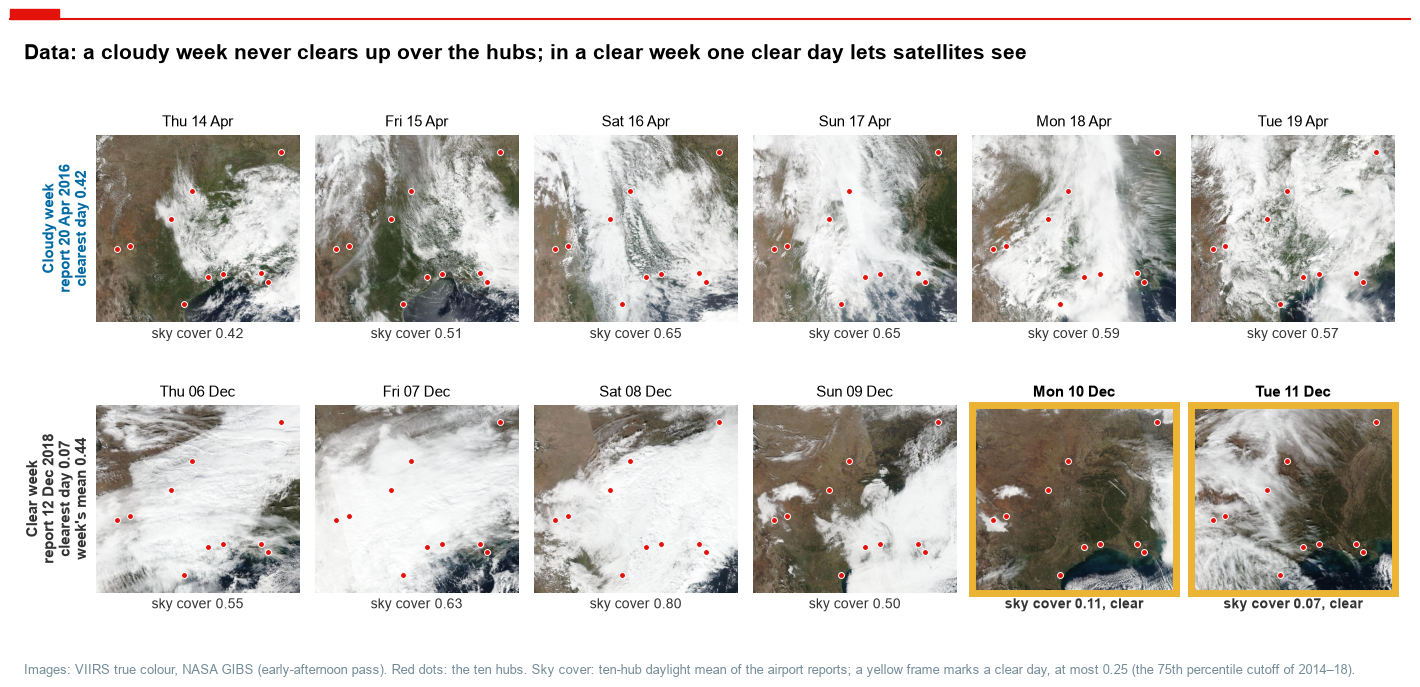

The weekly mean would label 50 of the 260 weeks of 2014–18 differently; cloudy weeks are most frequent in May (45% of its weeks in 2007–11 and 2014–18)


In [8]:
GIBS = "https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi"  # NASA's free satellite imagery service
MAP_BOX = (-105.0, 26.5, -87.5, 40.0)  # west, south, east, north: the ten hubs with a margin
FILMSTRIP = {  # reports of 2016-18 (VIIRS images start in November 2015)
    "Cloudy week": "2016-04-20",  # the week whose clearest day was the cloudiest
    "Clear week": "2018-12-12",  # the clearest single day among the weeks that the weekly mean calls cloudy
}


def satellite_image(day):
    '''True-colour VIIRS image (NASA GIBS) of the hub region on one day, cached in data/raw/gibs/.'''
    name = os.path.join("gibs", f"viirs_{day:%Y-%m-%d}.jpg")
    query = {"SERVICE": "WMS", "REQUEST": "GetMap", "VERSION": "1.1.1", "SRS": "EPSG:4326", "STYLES": "",
             "LAYERS": "VIIRS_SNPP_CorrectedReflectance_TrueColor", "FORMAT": "image/jpeg", "WIDTH": 700,
             "HEIGHT": 540, "BBOX": ",".join(map(str, MAP_BOX)), "TIME": f"{day:%Y-%m-%d}"}
    SOURCES[name] = f"{GIBS}?{urllib.parse.urlencode(query)}"
    return plt.imread(fetch(name))


cutoff = base["threshold"].iloc[0]
hub_lat, hub_lon = np.array([(lat, lon) for _, lat, lon in config.HUBS.values()]).T
fig, axes = plt.subplots(2, 6, figsize=(14, 6.3))
for row, (label, report) in enumerate(FILMSTRIP.items()):
    week = reports.loc[reports["release"] == pd.Timestamp(report)].iloc[0]
    days = pd.date_range(week["inventory_date"] - pd.Timedelta(days=1), week["release"] - pd.Timedelta(days=1))
    for ax, day in zip(axes[row], days):
        clear = daily_cloud[day] <= cutoff
        ax.imshow(satellite_image(day), extent=(MAP_BOX[0], MAP_BOX[2], MAP_BOX[1], MAP_BOX[3]))
        ax.set_aspect(1 / np.cos(np.radians(33)))  # true distances at the hubs' latitude
        ax.scatter(hub_lon, hub_lat, s=18, color=ECONOMIST_RED, edgecolor="white", lw=0.7, zorder=3)
        ax.set_title(f"{day:%a %d %b}", loc="center", fontsize=10.5, fontweight="bold" if clear else "normal")
        ax.set_xlabel(f"sky cover {daily_cloud[day]:.2f}" + (", clear" if clear else ""), fontsize=10,
                      fontweight="bold" if clear else "normal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():  # a yellow frame marks a clear day
            spine.set_visible(clear)
            spine.set_color(CLEAR)
            spine.set_linewidth(5)
    extra = "" if row == 0 else f"\nweek's mean {week['cloud_mean']:.2f}"
    axes[row, 0].set_ylabel(f"{label}\nreport {week['release']:%d %b %Y}\nclearest day {week['cloud_min']:.2f}{extra}",
                            fontsize=10.5, fontweight="bold", color=CLOUDY if row == 0 else DARK)
fig.text(0.01, -0.02, f"Images: VIIRS true colour, NASA GIBS (early-afternoon pass). Red dots: the ten hubs. Sky cover: "
         f"ten-hub daylight mean of the airport reports; a yellow frame marks a clear day, at most {cutoff:.2f} "
         f"(the 75th percentile cutoff of 2014–18).", fontsize=9, color=GREY)
show("Data: a cloudy week never clears up over the hubs; in a clear week one clear day lets satellites see")
pooled = pd.concat([pre, base])
season = pooled.groupby(pooled["release"].dt.month)["cloudy"].mean()
old_rule = base["cloud_mean"] > base["cloud_mean"].quantile(CLOUDY_QUANTILE)
print(f"The weekly mean would label {(old_rule != (base['cloudy'] == 1)).sum()} of the {len(base)} weeks of 2014–18 "
      f"differently; cloudy weeks are most frequent in {pd.Timestamp(2001, season.idxmax(), 1):%B} "
      f"({season.max():.0%} of its weeks in 2007–11 and 2014–18)")

**Comments – 1.3**
* **One clear day is enough:** in the April 2016 week the hubs stay under cloud from Thursday to Tuesday (clearest day 0.42). In the December 2018 week clouds cover them for four days, but Monday and Tuesday are clear (0.11 and 0.07), so satellites could count the oil before the Wednesday report.
* **The rule matters:** by its mean (0.44) the December week looks cloudy; the weekly mean, which our `03_cloudiness.py` used until now, labels 50 of the 260 weeks of 2014–18 differently.
* **Clouds are seasonal:** cloudy weeks are most frequent in May (45% of May weeks), so Task #4 compares weeks within the same quarter and 3.1 days within the same month.

### 1.4 Table 1: summary statistics, 2014–18
The returns differ by design: the paper's run from 10:30 to 11:00 a.m., ours from one settlement to the next.

In [9]:
PAPER_TABLE_1 = {  # paper, Table 1 (2014-18): observations, mean, median, standard deviation
    "Daily cloudiness": (1826, 0.35, 0.33, 0.16),
    "Oil inventory (million barrels)": (261, 434.37, 438.45, 57.56),
    "Oil return on report days (%)": (261, -0.08, -0.03, 1.13),
    "Implied oil variance, (OVX/100)²": (1258, 0.13, 0.10, 0.10),
}
first, last = PERIODS["2014–18"]
in_base = reports[reports["release"].between(first, last)]
ours = {
    "Daily cloudiness": daily_cloud[first:last],
    "Oil inventory (million barrels)": in_base["stocks"],
    "Oil return on report days (%)": in_base["ret"].dropna(),
    "Implied oil variance, (OVX/100)²": (ovx[first:last] / 100) ** 2,
}
STATISTICS = ["Obs.", "Mean", "Median", "St. dev."]
table_1 = pd.concat({
    "Ours": pd.DataFrame({name: [series.count(), series.mean(), series.median(), series.std()]
                          for name, series in ours.items()}, index=STATISTICS).T,
    "Paper": pd.DataFrame(PAPER_TABLE_1, index=STATISTICS).T,
}, axis=1)
table_1.style.format("{:,.2f}").format("{:,.0f}", subset=[("Ours", "Obs."), ("Paper", "Obs.")])

In [10]:
cloudy_size, clear_size = (base.loc[base["cloudy"] == flag, "x"].abs() for flag in (1, 0))
print(f"Exclusion check: the absolute surprise is {cloudy_size.mean():.2f} SD in cloudy and {clear_size.mean():.2f} SD "
      f"in clear weeks (t-test p = {ttest_ind(cloudy_size, clear_size, equal_var=False).pvalue:.2f})")

Exclusion check: the absolute surprise is 0.73 SD in cloudy and 0.82 SD in clear weeks (t-test p = 0.29)


**Comments – Task #1**
* **Our data match the paper's:** 261 reports with mean stocks of 433.95 million barrels (paper 434.37), and 1,258 OVX days whose implied variance has the paper's mean, median and SD (0.13, 0.10, 0.10). Our daily cloudiness is a little lower (mean 0.33 against 0.35), partly because `04_build_long_sample.py` picks each hub's airport anew every year: with one fixed airport per hub (`03_cloudiness.py`) the mean is 0.34, and the main result barely moves (Task #4).
* **Release dates:** the rule finds 745 of the 751 archived dates; the six misses are special cases (Hurricane Sandy, the 2013 shutdown, a national day of mourning in 2018, the 2021 inauguration, two year ends), so the 2007–11 dates, which rest on the rule, should be right. One report day (2 June 2016) has no EIA settlement price, so 2014–18 keeps 260 weeks.
* **Clouds do not predict the size of the news:** the absolute surprise is 0.73 SD in cloudy and 0.82 SD in clear weeks (p = 0.29), in line with the paper's Table IA-1.

## Task #2 – Main result: the price impact of the EIA report in clear and cloudy weeks
### 2.1 What daily returns can detect
The paper's 30-minute return sees almost only the report; a daily return also carries the day's other news. So before the results: how often would a 5% test find the paper's gap of −0.46 if it were true?

In [11]:
PAPER_GAP = -0.46  # Table 2, 10:30-11:00 a.m.: cloudy minus clear reaction per 1 SD surprise (%)
PAPER_WINDOW_SD = 1.13  # Table 1: standard deviation of the 10:30-11:00 a.m. return (%)


def power(sd, n_clear, n_cloudy, gap=PAPER_GAP):
    '''Chance that a two-sided 5% test finds a true gap, with return noise of standard deviation sd.'''
    z = abs(gap) / (sd * np.sqrt(1 / n_clear + 1 / n_cloudy))
    return norm.cdf(z - Z_95) + norm.cdf(-z - Z_95)


n_cloudy = int(base["cloudy"].sum())
n_clear = len(base) - n_cloudy
print(f"Power against the paper's gap: {power(PAPER_WINDOW_SD, n_clear, n_cloudy):.0%} with its 30-minute returns "
      f"(SD {PAPER_WINDOW_SD:.2f}%), {power(base['ret'].std(), n_clear, n_cloudy):.0%} with our daily returns "
      f"(SD {base['ret'].std():.2f}%)")

Power against the paper's gap: 81% with its 30-minute returns (SD 1.13%), 25% with our daily returns (SD 2.52%)


**Comment – 2.1:** our daily returns are 2.2 times as noisy as the paper's 30-minute returns (SD 2.52% against 1.13%): they also contain the API's private survey of Tuesday 4:30 p.m. and, on eight Wednesdays a year, the Fed's 2 p.m. statement. Even if the paper is right, we find its gap only one time in four (25% power, against 81%). **A gap that is not significant is therefore no evidence against the paper; what we can compare is its sign and size.**

### 2.2 Tables 2 and 3: clear against cloudy weeks
Eq. (1) of the paper: ret = α + β_clear · ΔInv · Clear + β_cloudy · ΔInv · Cloudy + ε, with ΔInv the surprise scaled to unit standard deviation. Like the paper we report bootstrap p-values (5,000 draws of weeks). The placebo of Table 3 uses returns on days without a report; we take the two trading days after the report, because the days before it are exactly where clear weeks should move (Table 6).

In [12]:
BOOT_DRAWS = 5_000  # bootstrap draws behind every p-value and interval
SEED = 20598  # every bootstrap starts from this seed, so reruns give the same numbers


def ols(y, X):
    '''OLS coefficients (k x m) of y (n x m) on X (n x k); also for stacks of samples along a first axis.'''
    Xt = np.swapaxes(X, -1, -2)
    return np.linalg.solve(Xt @ X, Xt @ y)


def bootstrap_draws(y, X, groups=None):
    '''Coefficients of BOOT_DRAWS samples of rows drawn with replacement; rows of one group stay together.'''
    rng = np.random.default_rng(SEED)
    if groups is None:
        rows = rng.integers(0, len(y), size=(BOOT_DRAWS, len(y)))
        return ols(y[rows], X[rows])
    members = [np.flatnonzero(groups == group) for group in pd.unique(groups)]
    picks = rng.integers(0, len(members), size=(BOOT_DRAWS, len(members)))
    return np.array([ols(y[rows], X[rows]) for rows in (np.concatenate([members[i] for i in pick]) for pick in picks)])


def p_value(draws):
    '''Two-sided bootstrap p-value: twice the share of draws on the far side of zero.'''
    return min(1.0, 2 * min((draws <= 0).mean(), (draws >= 0).mean()))


def regress(table, terms, outcome="ret", groups=None, controls=()):
    '''OLS of outcome on a constant, the named terms and controls. Returns estimate, bootstrap p-value and
    95% interval for each term and for "gap" (second term minus first), with R² and n in attrs.'''
    X = np.column_stack([np.ones(len(table)), *terms.values(), *(table[c] for c in controls)]).astype(float)
    y = table[[outcome]].to_numpy(float)
    beta = ols(y, X)[:, 0]
    draws = bootstrap_draws(y, X, groups)[:, :, 0]
    estimates = {name: (beta[i], draws[:, i]) for i, name in enumerate(terms, start=1)}
    if len(terms) == 2:
        estimates["gap"] = (beta[2] - beta[1], draws[:, 2] - draws[:, 1])
    result = pd.DataFrame({name: {"estimate": value, "p": p_value(d), "low": np.percentile(d, 2.5),
                                  "high": np.percentile(d, 97.5)} for name, (value, d) in estimates.items()}).T
    residuals = y[:, 0] - X @ beta
    result.attrs = {"r2": 1 - residuals.var() / y[:, 0].var(), "n": len(table)}
    return result


def reaction(sample, outcome="ret", groups=None, controls=()):
    '''Eq. (1): the clear and cloudy reactions to a 1 SD surprise, and their gap.'''
    terms = {"clear": sample["x"] * (1 - sample["cloudy"]), "cloudy": sample["x"] * sample["cloudy"]}
    return regress(sample, terms, outcome, groups, controls)


def days_after(sample, offsets=(1, 2)):
    '''Daily returns of the trading days `offsets` after each report, with the week's surprise and dummy.'''
    position = returns.index.get_indexer(sample["release"])
    rows = [sample.assign(ret=returns.iloc[position + offset].to_numpy()) for offset in offsets]
    return pd.concat(rows).sort_values("release")


def stars(p):
    '''Significance stars at the 10%, 5% and 1% levels, as in the paper.'''
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


def paper_style(result, rows=("β clear", "β cloudy", "Difference")):
    '''A column in the format of the paper's tables: estimate with stars and (p-value), R², observations.'''
    cells = [minus_sign(f"{value:.2f}{stars(p)} ({p:.2f})") for value, p in zip(result["estimate"], result["p"])]
    return pd.Series([*cells, f"{result.attrs['r2']:.2f}", f"{result.attrs['n']:,}"], index=[*rows, "R²", "Observations"])


def paper_column(numbers, rows=("β clear", "β cloudy", "Difference")):
    '''The paper's published column: ((estimate, p) for each row, R², observations).'''
    *estimates, r2, n = numbers
    cells = [minus_sign(f"{value:.2f}{stars(p)} ({p:.2f})") for value, p in estimates]
    return pd.Series([*cells, f"{r2:.2f}", f"{n:,}"], index=[*rows, "R²", "Observations"])


PAPER_TABLES_2_3 = {  # 10:30-11:00 a.m. returns: (estimate, p) for clear, cloudy, difference; R²; observations
    "2014–18": ((-0.05, 0.50), (-0.51, 0.00), (-0.46, 0.00), 0.05, 261),
    "2007–11": ((-0.43, 0.00), (-0.31, 0.02), (0.12, 0.43), 0.12, 261),
    "no report": ((-0.01, 0.69), (0.03, 0.33), (0.03, 0.31), 0.00, 992),
}
results = {"2014–18": reaction(base), "2007–11": reaction(pre)}
after = days_after(base)
results["no report"] = reaction(after, groups=after["release"].to_numpy())
pd.concat({
    ("Table 2: baseline 2014–18", "Ours, daily"): paper_style(results["2014–18"]),
    ("Table 2: baseline 2014–18", "Paper, 30 min"): paper_column(PAPER_TABLES_2_3["2014–18"]),
    ("Table 3: pre-period 2007–11", "Ours, daily"): paper_style(results["2007–11"]),
    ("Table 3: pre-period 2007–11", "Paper, 30 min"): paper_column(PAPER_TABLES_2_3["2007–11"]),
    ("Table 3: no report, 2014–18", "Ours, 2 days after"): paper_style(results["no report"]),
    ("Table 3: no report, 2014–18", "Paper, other days"): paper_column(PAPER_TABLES_2_3["no report"]),
}, axis=1)

Table 2: baseline 2014–18                   \
                           Ours, daily    Paper, 30 min   
β clear                  −0.31* (0.05)     −0.05 (0.50)   
β cloudy                −0.89** (0.05)  −0.51*** (0.00)   
Difference                −0.59 (0.19)  −0.46*** (0.00)   
R²                                0.04             0.05   
Observations                       260              261   

             Table 3: pre-period 2007–11                   \
                             Ours, daily    Paper, 30 min   
β clear                   −0.58** (0.02)  −0.43*** (0.00)   
β cloudy                    −0.45 (0.23)   −0.31** (0.02)   
Difference                   0.13 (0.76)      0.12 (0.43)   
R²                                  0.03             0.12   
Observations                         261              261   

             Table 3: no report, 2014–18                    
                      Ours, 2 days after Paper, other days  
β clear                      0.05 (0.56)      −0.01 (0.69)  
β cloudy                    −0.12 (0.44)       0.03 (0.33)  
Difference                  −0.17 (0.33)       0.03 (0.31)  
R²                                  0.00              0.00  
Observations                         520               992

HC1 instead of bootstrap p-values for the gap: 0.21 (2014–18), 0.77 (2007–11)


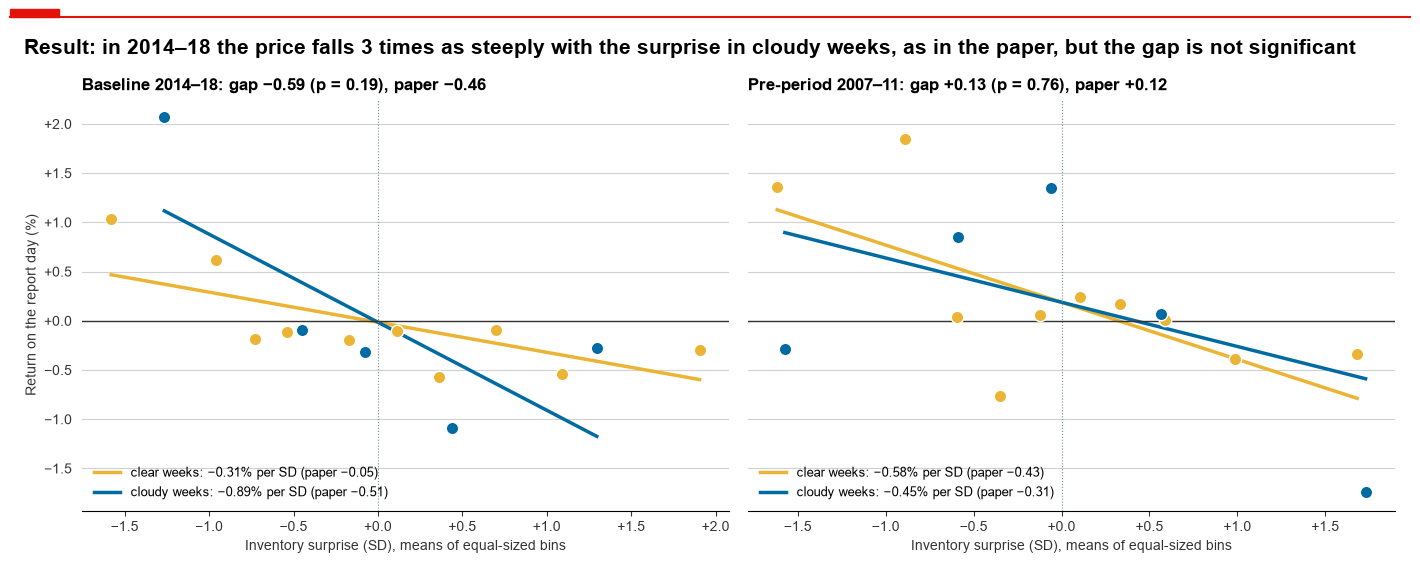

In [13]:
def robust_gap_p(sample):
    '''p-value of the cloudy minus clear gap with heteroskedasticity-robust (HC1) errors (paper, Table IA-2).'''
    X = sm.add_constant(pd.DataFrame({"clear": sample["x"] * (1 - sample["cloudy"]),
                                      "cloudy": sample["x"] * sample["cloudy"]}))
    return float(sm.OLS(sample["ret"], X).fit(cov_type="HC1").t_test("cloudy - clear = 0").pvalue)


print(f"HC1 instead of bootstrap p-values for the gap: {robust_gap_p(base):.2f} (2014–18), "
      f"{robust_gap_p(pre):.2f} (2007–11)")

SURPRISE_BINS = {0: 10, 1: 5}  # equal-sized bins of the surprise: clear weeks (about 20 each), cloudy (13 each)


def binned(sample, cloudy):
    '''Mean surprise and mean report-day return in equal-sized bins of the surprise, clear (0) or cloudy (1) weeks.'''
    group = sample[sample["cloudy"] == cloudy]
    bins = pd.qcut(group["x"].rank(method="first"), SURPRISE_BINS[cloudy], labels=False)
    return group.groupby(bins)[["x", "ret"]].mean()


fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
for ax, (period, sample) in zip(axes, [("2014–18", base), ("2007–11", pre)]):
    slope, paper = results[period]["estimate"], PAPER_TABLES_2_3[period]
    constant = (sample["ret"] - slope["clear"] * sample["x"] * (1 - sample["cloudy"])
                - slope["cloudy"] * sample["x"] * sample["cloudy"]).mean()  # the OLS intercept of Eq. (1)
    for cloudy, name, color, published in [(0, "clear", CLEAR, paper[0][0]), (1, "cloudy", CLOUDY, paper[1][0])]:
        points = binned(sample, cloudy)
        line = np.array([points["x"].min(), points["x"].max()])
        ax.plot(line, constant + slope[name] * line, color=color, lw=2.5,
                label=minus_sign(f"{name} weeks: {slope[name]:+.2f}% per SD (paper {published:+.2f})"))
        ax.scatter(points["x"], points["ret"], s=80, color=color, edgecolor="white", lw=1, zorder=3)
    ax.axhline(0, color=DARK, lw=1)
    ax.axvline(0, color=GREY, lw=0.8, ls=":")
    gap = results[period].loc["gap"]
    ax.set_title(minus_sign(f"{'Baseline' if period == '2014–18' else 'Pre-period'} {period}: gap {gap['estimate']:+.2f} "
                            f"(p = {gap['p']:.2f}), paper {paper[2][0]:+.2f}"), fontsize=12.5)
    ax.set_xlabel("Inventory surprise (SD), means of equal-sized bins")
    ax.xaxis.set_major_formatter(SIGNED)
    ax.yaxis.set_major_formatter(SIGNED)
    ax.legend(loc="lower left", fontsize=9.5)
axes[0].set_ylabel("Return on the report day (%)")
ratio = results["2014–18"].loc["cloudy", "estimate"] / results["2014–18"].loc["clear", "estimate"]
show(f"Result: in 2014–18 the price falls {ratio:.0f} times as steeply with the surprise in cloudy weeks, as in the "
     f"paper, but the gap is not significant")

**Comments – 2.2**
* **Same sign and size as the paper, not significant:** in 2014–18 a 1 SD inventory surprise lowers the price by 0.89% in cloudy and 0.31% in clear weeks (paper: 0.51% and 0.05%). Our gap of −0.59 is even larger than the paper's −0.46, but has p = 0.19 (0.21 with robust errors), as 2.1 predicts.
* **The placebos hold:** in 2007–11 clear and cloudy weeks react alike (gap +0.13, paper +0.12), and on the two days after a report the surprise moves nothing (gap −0.17, p = 0.33).
* **Clear weeks still react over the day** (−0.31, p = 0.05, against −0.05 in the paper's 30 minutes), possibly through the API survey of Tuesday evening, which lies in our window but before the paper's.

### 2.3 Figure 5 at daily frequency: when does the price move?
The paper's Figure 5 widens the return window in 15-minute steps from 9:30 a.m. With daily data we widen it day by day instead: cumulative returns from the settlement on the Thursday before the inventory date, the first day of the cloud window, to each day around the report. If satellites inform the market, clear weeks move **before** the report and cloudy weeks **on** it, and both end at a similar total.

The second chart lays the paper's Figure 5 over ours. To compare like with like, it measures our returns from Tuesday's settlement, the last price before the report, as the paper's run from 9:30 a.m.; the paper's lines are read off its published figure (about ±0.01).

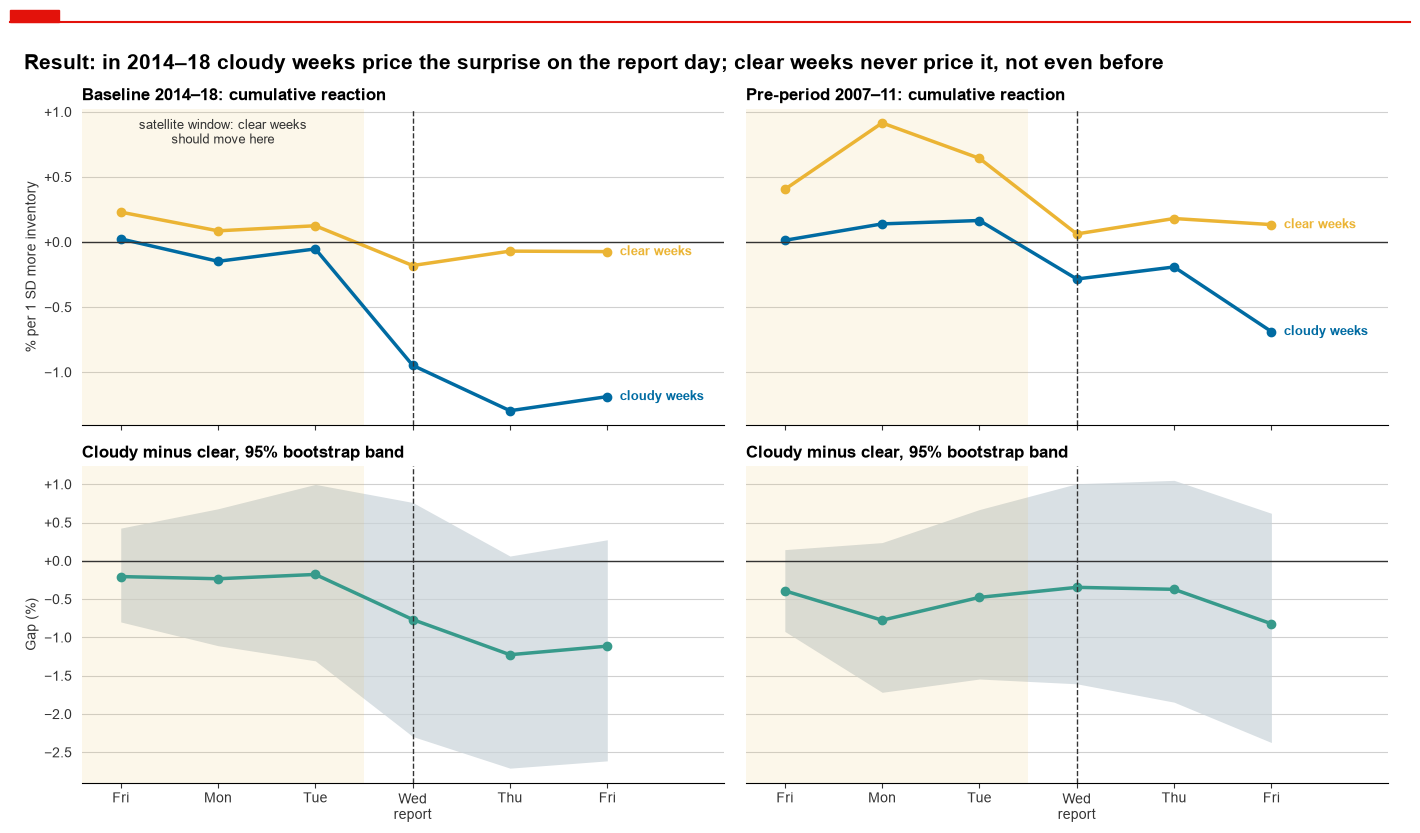

2014–18: cloudy weeks −0.95 by the report day and −1.19 by Friday; clear weeks between −0.18 and +0.23 on every day; gap by Friday −1.11 [−2.61, +0.27]


In [14]:
EVENT_DAYS = np.arange(-3, 3)  # trading days relative to the report
START_DAY = -4  # cumulative returns start at the settlement of the Thursday before the inventory date
DAY_LABELS = ["Fri", "Mon", "Tue", "Wed\nreport", "Thu", "Fri"]  # for a Wednesday report


def event_paths(sample, start=START_DAY, days=EVENT_DAYS):
    '''β clear, β cloudy and their gap for cumulative returns from the settlement of event day `start` to each
    of `days`, with 95% bootstrap bands (the same draws of weeks for every day).'''
    level = returns.cumsum()  # log price index, in %
    position = level.index.get_indexer(sample["release"])
    y = np.column_stack([level.iloc[position + day].to_numpy() - level.iloc[position + start].to_numpy()
                         for day in days])
    X = np.column_stack([np.ones(len(sample)), sample["x"] * (1 - sample["cloudy"]), sample["x"] * sample["cloudy"]])
    beta, draws = ols(y, X), bootstrap_draws(y, X)
    paths = {"clear": (beta[1], draws[:, 1]), "cloudy": (beta[2], draws[:, 2]),
             "gap": (beta[2] - beta[1], draws[:, 2] - draws[:, 1])}
    return {name: pd.DataFrame({"estimate": value, "low": np.percentile(d, 2.5, axis=0),
                                "high": np.percentile(d, 97.5, axis=0)}, index=days)
            for name, (value, d) in paths.items()}


paths = {period: event_paths(sample) for period, sample in [("2014–18", base), ("2007–11", pre)]}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey="row")
for column, period in enumerate(paths):
    top, bottom = axes[0, column], axes[1, column]
    for name, color in [("clear", CLEAR), ("cloudy", CLOUDY)]:
        path = paths[period][name]
        top.plot(EVENT_DAYS, path["estimate"], color=color, lw=2.5, marker="o")
        annotate(top, f"{name} weeks", (EVENT_DAYS[-1], path["estimate"].iloc[-1]), color=color, fontweight="bold")
    gap = paths[period]["gap"]
    bottom.fill_between(EVENT_DAYS, gap["low"], gap["high"], color=LIGHT_GREY, alpha=0.7, lw=0)
    bottom.plot(EVENT_DAYS, gap["estimate"], color=GAP, lw=2.5, marker="o")
    for ax in (top, bottom):
        ax.axvspan(-3.4, -0.5, color=CLEAR, alpha=0.1, lw=0)  # days on which satellites can inform clear weeks
        ax.axhline(0, color=DARK, lw=1)
        ax.axvline(0, color=DARK, lw=1, ls="--")
        ax.yaxis.set_major_formatter(SIGNED)
        ax.set_xlim(-3.4, 3.2)
    if column == 0:
        top.text(-1.95, 0.97, "satellite window: clear weeks\nshould move here", transform=top.get_xaxis_transform(),
                 ha="center", va="top", fontsize=9, color=DARK)
    top.set_title(f"{'Baseline' if period == '2014–18' else 'Pre-period'} {period}: cumulative reaction", fontsize=12.5)
    bottom.set_title("Cloudy minus clear, 95% bootstrap band", fontsize=12.5)
    bottom.set_xticks(EVENT_DAYS, DAY_LABELS)
axes[0, 0].set_ylabel("% per 1 SD more inventory")
axes[1, 0].set_ylabel("Gap (%)")
show("Result: in 2014–18 cloudy weeks price the surprise on the report day; clear weeks never price it, not even before")
clear_path, cloudy_path = paths["2014–18"]["clear"]["estimate"], paths["2014–18"]["cloudy"]["estimate"]
print(minus_sign(f"2014–18: cloudy weeks {cloudy_path.loc[0]:+.2f} by the report day and {cloudy_path.loc[2]:+.2f} by Friday; "
                 f"clear weeks between {clear_path.min():+.2f} and {clear_path.max():+.2f} on every day; "
                 f"gap by Friday {paths['2014–18']['gap'].loc[2, 'estimate']:+.2f} "
                 f"[{paths['2014–18']['gap'].loc[2, 'low']:+.2f}, {paths['2014–18']['gap'].loc[2, 'high']:+.2f}]"))

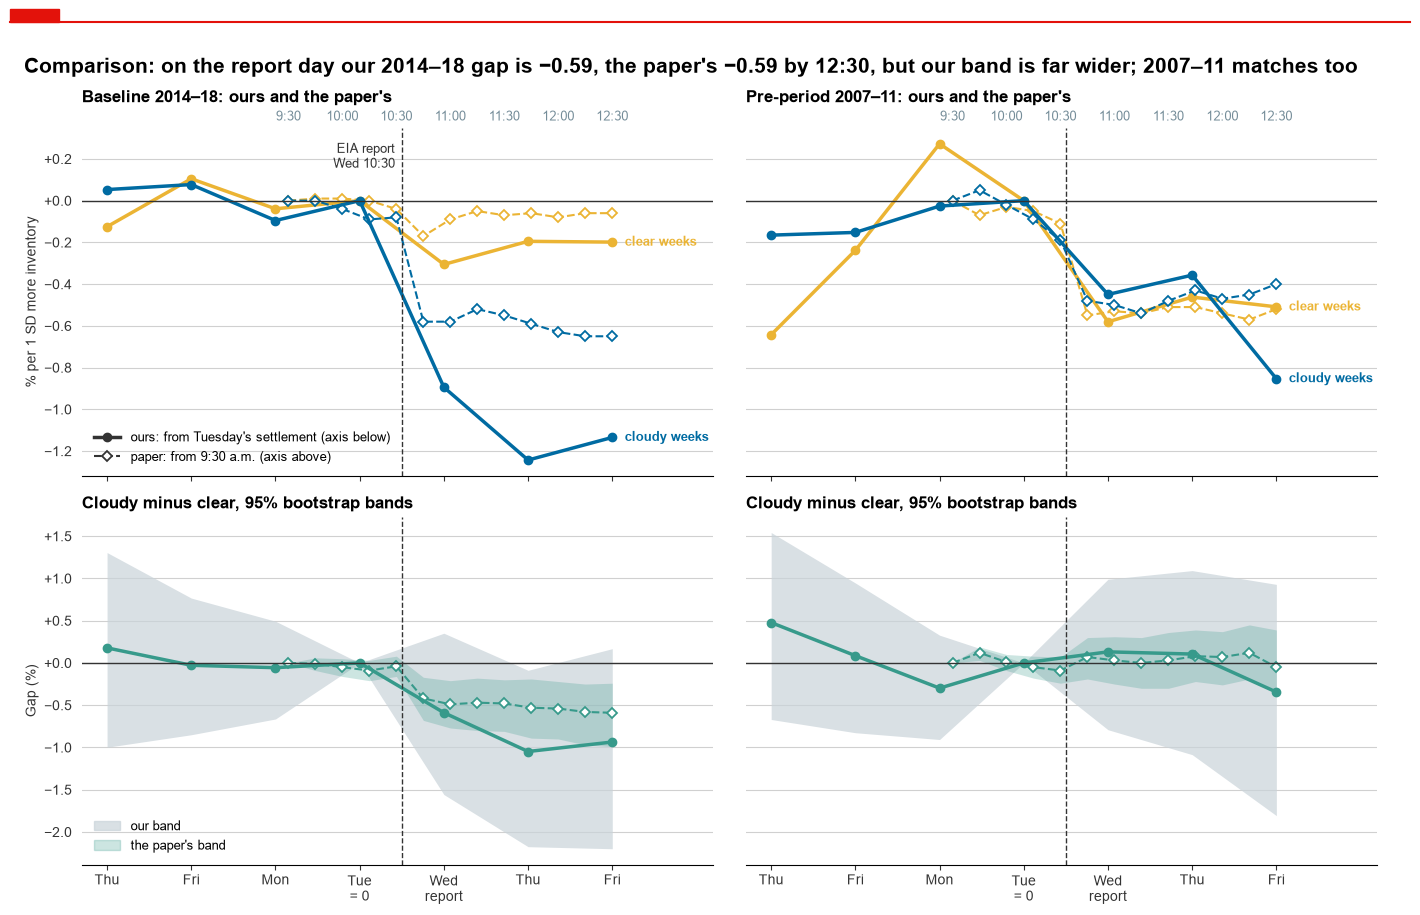

2014–18, Tuesday to Wednesday settlement (paper: 9:30 to 12:30): clear −0.31 (−0.06), cloudy −0.89 (−0.65), gap −0.59 [−1.56, +0.35] (−0.59 [−0.99, −0.24]); by Friday: gap −0.94 [−2.20, +0.17]
2007–11, Tuesday to Wednesday settlement (paper: 9:30 to 12:30): clear −0.58 (−0.52), cloudy −0.45 (−0.40), gap +0.13 [−0.79, +0.99] (−0.05 [−0.32, +0.39]); by Friday: gap −0.34 [−1.81, +0.93]


In [15]:
# The paper's Figure 5, read off the published image (about ±0.01; at 11:30 it matches Tables 2 and 3): slopes for
# returns from 9:30 a.m. to each quarter hour until 12:30, their gap (cloudy minus clear) and its 95% bootstrap band.
# The published figure's last pre-period gap (−0.05) differs from its cloudy minus clear (+0.12); we plot both as published.
PAPER_MINUTES = np.arange(0, 181, 15)  # end of each return horizon, in minutes after 9:30
PAPER_FIGURE_5 = {
    "2014–18": {"clear": [0, .01, .01, 0, -.04, -.17, -.09, -.05, -.07, -.06, -.08, -.06, -.06],
                "cloudy": [0, 0, -.04, -.09, -.08, -.58, -.58, -.52, -.55, -.59, -.63, -.65, -.65],
                "gap": [0, -.01, -.05, -.09, -.04, -.42, -.49, -.47, -.48, -.53, -.54, -.58, -.59],
                "low": [0, -.09, -.16, -.21, -.16, -.68, -.77, -.80, -.81, -.89, -.90, -.97, -.99],
                "high": [0, .06, .05, .03, .08, -.17, -.21, -.18, -.20, -.19, -.22, -.25, -.24]},
    "2007–11": {"clear": [0, -.07, -.03, -.05, -.11, -.55, -.53, -.54, -.51, -.51, -.54, -.57, -.52],
                "cloudy": [0, .05, -.02, -.09, -.19, -.48, -.50, -.54, -.48, -.43, -.47, -.45, -.40],
                "gap": [0, .12, .01, -.05, -.09, .07, .03, 0, .03, .08, .07, .12, -.05],
                "low": [0, .03, -.09, -.18, -.24, -.19, -.25, -.30, -.30, -.22, -.26, -.19, -.32],
                "high": [0, .19, .10, .08, .07, .30, .31, .30, .36, .39, .37, .45, .39]}}
REPORT_X = -0.5  # on our axis the report comes out between Tuesday's and Wednesday's settlement
PAPER_REPORT = 63  # on the paper's axis just after 10:30 (its dashed line), in minutes after 9:30
PAPER_SCALE = (PAPER_MINUTES[-1] - PAPER_REPORT) / (EVENT_DAYS[-1] - REPORT_X)  # paper minutes per day, drawing only


def paper_x(minutes):
    '''Position on our day axis of the paper's horizon ending `minutes` after 9:30: the two time axes meet at
    the report, and the paper's 12:30 sits on our Friday.'''
    return REPORT_X + (np.asarray(minutes) - PAPER_REPORT) / PAPER_SCALE


def paper_minutes(x):
    '''Inverse of paper_x, for the paper's clock on top of the chart.'''
    return PAPER_REPORT + (np.asarray(x) - REPORT_X) * PAPER_SCALE


DAYS = np.arange(START_DAY, EVENT_DAYS[-1] + 1)  # Thursday before the inventory date to Friday after the report
# Like the paper's returns from 9:30 a.m., ours now start from the last price before the report, Tuesday's settlement
from_tuesday = {period: event_paths(sample, start=-1, days=DAYS) for period, sample in [("2014–18", base), ("2007–11", pre)]}
OURS = {"lw": 2.5, "marker": "o"}
PAPERS = {"lw": 1.5, "ls": "--", "marker": "D", "ms": 5.5, "mfc": "white", "mew": 1.3}
fig, axes = plt.subplots(2, 2, figsize=(14, 8.8), sharex=True, sharey="row")
for column, period in enumerate(from_tuesday):
    top, bottom, paper = axes[0, column], axes[1, column], PAPER_FIGURE_5[period]
    for name, color in [("clear", CLEAR), ("cloudy", CLOUDY)]:
        ours = from_tuesday[period][name]["estimate"]
        top.plot(paper_x(PAPER_MINUTES), paper[name], color=color, **PAPERS)
        top.plot(DAYS, ours, color=color, **OURS)
        annotate(top, f"{name} weeks", (DAYS[-1], ours.iloc[-1]), color=color, fontweight="bold")
    gap = from_tuesday[period]["gap"]
    bottom.fill_between(DAYS, gap["low"], gap["high"], color=LIGHT_GREY, alpha=0.7, lw=0)
    bottom.fill_between(paper_x(PAPER_MINUTES), paper["low"], paper["high"], color=GAP, alpha=0.25, lw=0)
    bottom.plot(paper_x(PAPER_MINUTES), paper["gap"], color=GAP, **PAPERS)
    bottom.plot(DAYS, gap["estimate"], color=GAP, **OURS)
    for ax in (top, bottom):
        ax.axhline(0, color=DARK, lw=1)
        ax.axvline(REPORT_X, color=DARK, lw=1, ls="--")
        ax.yaxis.set_major_formatter(SIGNED)
        ax.set_xlim(-4.3, 3.2)
    clock = top.secondary_xaxis("top", functions=(paper_minutes, paper_x))
    clock.set_xticks(PAPER_MINUTES[::2], [f"{9 + (30 + m) // 60}:{(30 + m) % 60:02d}" for m in PAPER_MINUTES[::2]])
    clock.tick_params(colors=GREY, labelsize=9, length=0)
    clock.spines["top"].set_visible(False)
    top.set_title(f"{'Baseline' if period == '2014–18' else 'Pre-period'} {period}: ours and the paper's", fontsize=12.5)
    bottom.set_title("Cloudy minus clear, 95% bootstrap bands", fontsize=12.5)
    bottom.set_xticks(DAYS, ["Thu", "Fri", "Mon", "Tue\n= 0"] + DAY_LABELS[3:])
axes[0, 0].text(REPORT_X - 0.08, 0.96, "EIA report\nWed 10:30", transform=axes[0, 0].get_xaxis_transform(),
                ha="right", va="top", fontsize=9, color=DARK)
axes[0, 0].legend(handles=[plt.Line2D([], [], color=DARK, **OURS, label="ours: from Tuesday's settlement (axis below)"),
                           plt.Line2D([], [], color=DARK, **PAPERS, label="paper: from 9:30 a.m. (axis above)")],
                  loc="lower left", fontsize=9.5)
axes[1, 0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LIGHT_GREY, alpha=0.7, label="our band"),
                           plt.Rectangle((0, 0), 1, 1, color=GAP, alpha=0.25, label="the paper's band")],
                  loc="lower left", fontsize=9.5)
axes[0, 0].set_ylabel("% per 1 SD more inventory")
axes[1, 0].set_ylabel("Gap (%)")
report_gap = from_tuesday["2014–18"]["gap"].loc[0, "estimate"]
show(minus_sign(f"Comparison: on the report day our 2014–18 gap is {report_gap:+.2f}, the paper's "
                f"{PAPER_FIGURE_5['2014–18']['gap'][-1]:+.2f} by 12:30, but our band is far wider; 2007–11 matches too"))
for period, ours in from_tuesday.items():
    paper = PAPER_FIGURE_5[period]
    print(minus_sign(f"{period}, Tuesday to Wednesday settlement (paper: 9:30 to 12:30): "
                     f"clear {ours['clear'].loc[0, 'estimate']:+.2f} ({paper['clear'][-1]:+.2f}), "
                     f"cloudy {ours['cloudy'].loc[0, 'estimate']:+.2f} ({paper['cloudy'][-1]:+.2f}), "
                     f"gap {ours['gap'].loc[0, 'estimate']:+.2f} [{ours['gap'].loc[0, 'low']:+.2f}, "
                     f"{ours['gap'].loc[0, 'high']:+.2f}] ({paper['gap'][-1]:+.2f} [{paper['low'][-1]:+.2f}, "
                     f"{paper['high'][-1]:+.2f}]); by Friday: gap {ours['gap'].loc[2, 'estimate']:+.2f} "
                     f"[{ours['gap'].loc[2, 'low']:+.2f}, {ours['gap'].loc[2, 'high']:+.2f}]"))

**Comments – 2.3**
* **Cloudy weeks move on the report day:** per SD of surprise the price is 0.95% lower by the report day's settlement and 1.19% by Friday, and almost all of it comes on Wednesday.
* **Clear weeks never move:** their reaction stays between −0.18 and +0.23 on every day. If satellites had revealed the inventory change, this line would fall before Wednesday and end near the cloudy one. So our data back the first half of the paper's story (the report is news only in cloudy weeks), but do not show where the information goes in clear weeks; with a band of −2.61 to +0.27 for the gap by Friday, they cannot rule much out.
* **Next to the paper's Figure 5 (second chart):** in 2007–11 our report-day reactions are the paper's (clear −0.58 against −0.52 by 12:30, cloudy −0.45 against −0.40). In 2014–18 both our lines end about 0.25 lower, a move common to clear and cloudy weeks outside the paper's 9:30 to 12:30 window (possibly the API survey, 2.2), so the gap is the paper's: −0.59. But our band for it runs from −1.56 to +0.35 (paper −0.99 to −0.24); it excludes zero only on Thursday (−1.05, band −2.17 to −0.09), one of three days after the report.

## Task #3 – Mechanism: uncertainty and timing
### 3.1 Table 5: implied volatility after cloudy and clear days
The paper regresses the OVX-implied variance of day t+1 on a cloudy-day dummy of day t (a satellite's estimate of day t reaches the market on t+1), with bootstrap p-values that treat days as independent. But OVX is very persistent and clouds are seasonal, so we add Newey-West errors and compare days within the same calendar month, or within the same month of the same year.

In [16]:
OVX_LAGS = 20  # Newey-West lags, about a month of trading days
PAPER_TABLE_5 = {"2014–18": (0.128, 0.143, 0.015, 0.02, 1258), "2007–11": (0.199, 0.201, 0.002, 0.82, 1170)}
# clear mean, cloudy mean, difference, its bootstrap p-value, observations


def ovx_days(period):
    '''Daily implied variance (OVX/100)² with the cloudy dummy of the previous calendar day.'''
    first, last = PERIODS[period]
    variance = (ovx[first:last] / 100) ** 2
    cloud = daily_cloud.reindex(variance.index - pd.Timedelta(days=1)).to_numpy()
    days = pd.DataFrame({"variance": variance, "cloud": cloud}).dropna()
    days["cloudy"] = (days["cloud"] > daily_cloud[first:last].quantile(CLOUDY_QUANTILE)).astype(float)
    return days


def ovx_gap(days, within=None):
    '''Cloudy minus clear implied variance with its Newey-West standard error; within = "calendar month"
    or "year and month" compares only days that share it.'''
    variance, cloudy = days["variance"], days["cloudy"]
    if within:
        key = days.index.month if within == "calendar month" else days.index.to_period("M")
        variance = variance - variance.groupby(key).transform("mean")
        cloudy = cloudy - cloudy.groupby(key).transform("mean")
    X = cloudy.to_frame() if within else sm.add_constant(cloudy)
    fit = sm.OLS(variance, X).fit(cov_type="HAC", cov_kwds={"maxlags": OVX_LAGS})
    return fit.params["cloudy"], fit.bse["cloudy"]


SPECS_5 = {  # label: comparison passed to ovx_gap
    "All days (paper)": None, "Same calendar month": "calendar month", "Same year and month": "year and month"}
table_5, gaps_5 = {}, {}
for period in PERIODS:
    days = ovx_days(period)
    paper_test = regress(days, {"cloudy": days["cloudy"]}, outcome="variance")  # i.i.d. bootstrap, as the paper
    clear_mean = days.loc[days["cloudy"] == 0, "variance"].mean()
    gaps_5[period] = {label: ovx_gap(days, within) for label, within in SPECS_5.items()}
    nw = {label: 2 * norm.sf(abs(gap / se)) for label, (gap, se) in gaps_5[period].items()}
    table_5[(period, "Ours")] = pd.Series({
        "β clear": f"{clear_mean:.3f}", "β cloudy": f"{clear_mean + paper_test.loc['cloudy', 'estimate']:.3f}",
        "Difference (bootstrap p)": minus_sign(f"{paper_test.loc['cloudy', 'estimate']:.3f} ({paper_test.loc['cloudy', 'p']:.2f})"),
        "Difference (Newey-West p)": minus_sign(f"{gaps_5[period]['All days (paper)'][0]:.3f} ({nw['All days (paper)']:.2f})"),
        "Same calendar month (NW p)": minus_sign(f"{gaps_5[period]['Same calendar month'][0]:.3f} ({nw['Same calendar month']:.2f})"),
        "Same year and month (NW p)": minus_sign(f"{gaps_5[period]['Same year and month'][0]:.3f} ({nw['Same year and month']:.2f})"),
        "Observations": f"{len(days):,}"})
    if period in PAPER_TABLE_5:
        clear, cloudy, gap, p, n = PAPER_TABLE_5[period]
        table_5[(period, "Paper")] = pd.Series({"β clear": f"{clear:.3f}", "β cloudy": f"{cloudy:.3f}",
                                                "Difference (bootstrap p)": f"{gap:.3f} ({p:.2f})", "Observations": f"{n:,}"})
ROWS_5 = ["β clear", "β cloudy", "Difference (bootstrap p)", "Difference (Newey-West p)", "Same calendar month (NW p)",
          "Same year and month (NW p)", "Observations"]
pd.DataFrame(table_5).reindex(ROWS_5).fillna("")

2007–11                      2014–18  \
                                     Ours         Paper           Ours   
β clear                             0.199         0.199          0.128   
β cloudy                            0.201         0.201          0.144   
Difference (bootstrap p)     0.001 (0.91)  0.002 (0.82)   0.016 (0.02)   
Difference (Newey-West p)    0.001 (0.94)                 0.016 (0.15)   
Same calendar month (NW p)  −0.022 (0.19)                −0.007 (0.49)   
Same year and month (NW p)  −0.001 (0.83)                −0.003 (0.12)   
Observations                        1,172         1,170          1,258   

                                                2019–24  
                                   Paper           Ours  
β clear                            0.128          0.241  
β cloudy                           0.143          0.275  
Difference (bootstrap p)    0.015 (0.02)   0.034 (0.31)  
Difference (Newey-West p)                  0.034 (0.54)  
Same calendar month (NW p)                −0.013 (0.78)  
Same year and month (NW p)                −0.016 (0.40)  
Observations                       1,258          1,326

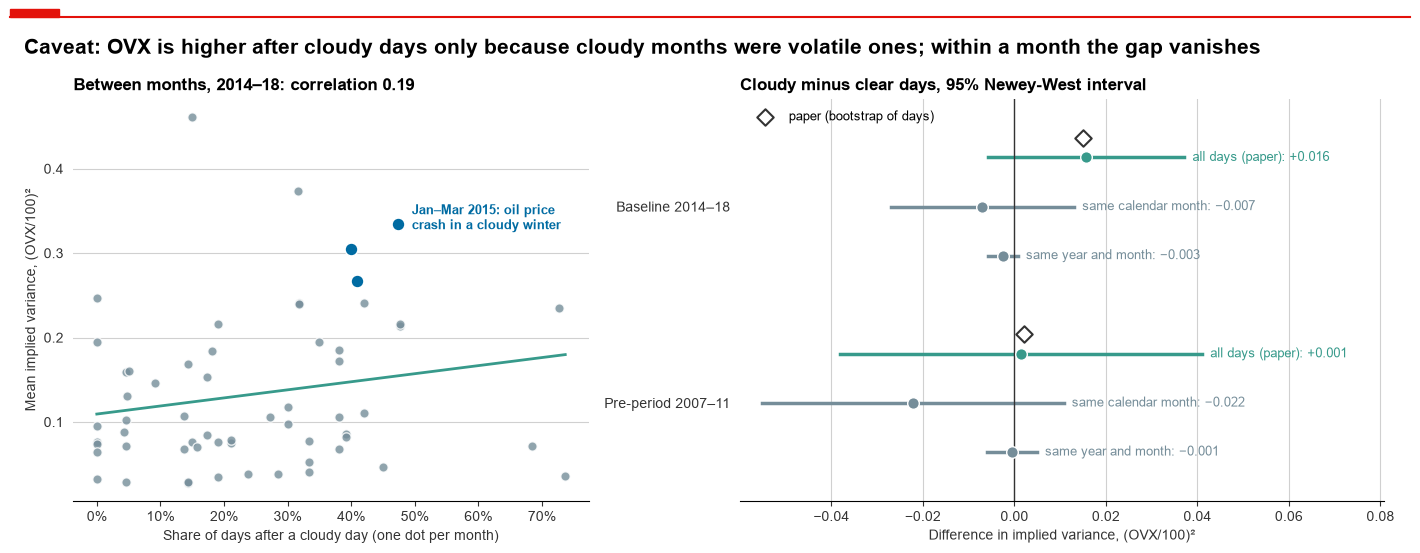

Monthly correlation of the cloudy share with implied variance: 0.19 (2014–18), −0.01 (2007–11); within a month of 2014–18, OVX is higher after cloudy days in 23 of 53 months


In [17]:
CRASH_MONTHS = pd.period_range("2015-01", "2015-03", freq="M")  # oil price crash in a cloudy winter
months = {}
for period in ("2014–18", "2007–11"):
    days = ovx_days(period)
    months[period] = days.groupby(days.index.to_period("M")).agg(cloudy_share=("cloudy", "mean"),
                                                                 variance=("variance", "mean"))
base_months = months["2014–18"]
crash = base_months.index.isin(CRASH_MONTHS)
slope, intercept = np.polyfit(base_months["cloudy_share"], base_months["variance"], 1)
correlation = {period: table["cloudy_share"].corr(table["variance"]) for period, table in months.items()}

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.3), gridspec_kw={"width_ratios": [1, 1.25]})
left.scatter(base_months.loc[~crash, "cloudy_share"], base_months.loc[~crash, "variance"], s=45, color=GREY,
             alpha=0.8, edgecolor="white")
left.scatter(base_months.loc[crash, "cloudy_share"], base_months.loc[crash, "variance"], s=85, color=CLOUDY,
             edgecolor="white", zorder=3)
annotate(left, "Jan–Mar 2015: oil price\ncrash in a cloudy winter",
         (base_months.loc[crash, "cloudy_share"].max(), base_months.loc[crash, "variance"].max()), offset=(10, 4),
         color=CLOUDY, fontweight="bold")
share = np.array([0, base_months["cloudy_share"].max()])
left.plot(share, intercept + slope * share, color=GAP, lw=2)
left.set_title(f"Between months, 2014–18: correlation {correlation['2014–18']:.2f}", fontsize=12.5)
left.set_xlabel("Share of days after a cloudy day (one dot per month)")
left.set_ylabel("Mean implied variance, (OVX/100)²")
left.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0%}"))

rows = {"2007–11": 0, "2014–18": 1}  # out of sample only in the table: April 2020 (OVX 325) dwarfs the scale
offsets = dict(zip(SPECS_5, [0.25, 0, -0.25]))
for period, row in rows.items():
    for label, (gap, se) in gaps_5[period].items():
        y = row + offsets[label]
        color = GAP if label == "All days (paper)" else GREY
        right.plot([gap - Z_95 * se, gap + Z_95 * se], [y, y], color=color, lw=2.5)
        right.scatter(gap, y, color=color, s=70, zorder=3, edgecolor="white")
        annotate(right, minus_sign(f"{label.lower()}: {gap:+.3f}"), (gap + Z_95 * se, y), offset=(6, 0), color=color)
    right.scatter(PAPER_TABLE_5[period][2], row + offsets["All days (paper)"] + 0.1, marker="D", s=70,
                  facecolor="white", edgecolor=PAPER, lw=1.5, zorder=4)  # just above our estimate, which it would hide
right.scatter([], [], marker="D", s=70, facecolor="white", edgecolor=PAPER, lw=1.5, label="paper (bootstrap of days)")
right.axvline(0, color=DARK, lw=1)
right.set_yticks(list(rows.values()), [f"{'Pre-period' if p == '2007–11' else 'Baseline'} {p}" for p in rows])
right.set_ylim(-0.5, 1.55)
right.set_xlim(right=right.get_xlim()[1] + 0.035)
right.set_title("Cloudy minus clear days, 95% Newey-West interval", fontsize=12.5)
right.set_xlabel("Difference in implied variance, (OVX/100)²")
right.legend(loc="upper left", fontsize=9.5)
vertical_grid(right)
show("Caveat: OVX is higher after cloudy days only because cloudy months were volatile ones; within a month the gap vanishes")
days = ovx_days("2014–18")
by_month = days.groupby([days.index.to_period("M"), "cloudy"])["variance"].mean().unstack().dropna()
print(minus_sign(f"Monthly correlation of the cloudy share with implied variance: {correlation['2014–18']:.2f} (2014–18), "
                 f"{correlation['2007–11']:.2f} (2007–11); within a month of 2014–18, OVX is higher after cloudy days "
                 f"in {(by_month[1.0] > by_month[0.0]).sum()} of {len(by_month)} months"))

**Comments – 3.1**
* **An exact replication:** after clear days the implied variance averages 0.128 and after cloudy days 0.144 (paper: 0.128 and 0.143), with the same bootstrap p-value of 0.02; in 2007–11 both are 0.199 and 0.201, as in the paper.
* **But the significance is not robust:** with Newey-West errors the 2014–18 gap has p = 0.15. Within the same calendar month it turns negative (−0.007), within the same month of the same year it is −0.003 (p = 0.12), and OVX is higher after cloudy days in only 23 of 53 months.
* **Where the paper's gap comes from:** across months, cloudier months were more volatile (correlation 0.19), above all the oil price crash of January to March 2015, a cloudy winter; in 2007–11 the correlation is −0.01. So a cloudy day does not raise uncertainty on the next day. Out of sample the gap is +0.034 (p = 0.54), with a wide interval: OVX reached 325 in April 2020.

### 3.2 Table 6: does the price move after the first clear day?
In clear weeks the surprise should enter the price on the first trading day after the first clear day, when the satellite estimate is published. We use the trading days from the inventory Friday to the day before the report; the report day's own return mixes in the report, so we match the paper's columns without it.

In [18]:
PAPER_TABLE_6 = {  # paper, Table 6, without the announcement day: (estimate, p) first clear, other, difference; R²; n
    "2014–18": ((-0.20, 0.10), (-0.08, 0.34), (-0.12, 0.39), 0.00, 753),
    "2007–11": ((-0.06, 0.66), (0.05, 0.54), (-0.11, 0.47), 0.00, 707),
}


def first_clear_days(sample):
    '''Returns of the trading days from the inventory Friday to the day before the report in clear weeks,
    flagged when the day is the first trading day after the week's first clear day.'''
    rows = []
    for week in sample[sample["cloudy"] == 0].itertuples():
        window = daily_cloud.loc[week.inventory_date - pd.Timedelta(days=1): week.release - pd.Timedelta(days=1)]
        first_clear = window[window <= week.threshold].index[0]
        days = returns.loc[week.inventory_date: week.release - pd.Timedelta(days=1)]
        news_day = days.index[days.index > first_clear]  # the estimate of a day comes out the next morning
        rows += [{"release": week.release, "x": week.x, "ret": ret,
                  "first_clear": float(len(news_day) > 0 and day == news_day[0])} for day, ret in days.items()]
    return pd.DataFrame(rows)


results_6 = {}
for period in PERIODS:
    days = first_clear_days(weeks_of(period))
    terms = {"other": days["x"] * (1 - days["first_clear"]), "first clear": days["x"] * days["first_clear"]}
    results_6[period] = regress(days, terms, groups=days["release"].to_numpy())
ROWS_6 = ("β other days", "β first clear", "Difference")
pd.concat({
    ("2014–18", "Ours"): paper_style(results_6["2014–18"], ROWS_6),
    ("2014–18", "Paper"): paper_column([PAPER_TABLE_6["2014–18"][i] for i in (1, 0, 2)] + list(PAPER_TABLE_6["2014–18"][3:]), ROWS_6),
    ("2007–11", "Ours"): paper_style(results_6["2007–11"], ROWS_6),
    ("2007–11", "Paper"): paper_column([PAPER_TABLE_6["2007–11"][i] for i in (1, 0, 2)] + list(PAPER_TABLE_6["2007–11"][3:]), ROWS_6),
    ("2019–24", "Ours"): paper_style(results_6["2019–24"], ROWS_6),
}, axis=1)

2014–18                     2007–11                \
                       Ours         Paper          Ours         Paper   
β other days    0.15 (0.20)  −0.08 (0.34)   0.09 (0.53)   0.05 (0.54)   
β first clear  −0.17 (0.37)  −0.20 (0.10)  0.38* (0.09)  −0.06 (0.66)   
Difference     −0.31 (0.17)  −0.12 (0.39)   0.30 (0.27)  −0.11 (0.47)   
R²                     0.00          0.00          0.01          0.00   
Observations            589           753           586           707   

                    2019–24  
                       Ours  
β other days   −0.16 (0.27)  
β first clear  −0.22 (0.44)  
Difference     −0.06 (0.86)  
R²                     0.00  
Observations            613

**Comments – 3.2**
* **2014–18 points the paper's way, without significance:** per SD of surprise the price moves −0.17% on the first trading day after the first clear day (paper −0.20%) and +0.15% on the other days, a gap of −0.31 (p = 0.17; paper −0.12, p = 0.39). Neither the paper's nor our evidence shows that the information enters the price on that day.
* **The pre-period does not fit:** +0.38% on the day after the first clear day (p = 0.09), where the paper finds −0.06%; out of sample the gap is −0.06 (p = 0.86).

## Task #4 – Robustness of the main result
The Internet Appendix (Tables IA-2 and IA-3) varies the cutoff, the expectation model, the daylight hours and treats outliers. We add the week's mean instead of its least cloudy day, a window without the Thursday, one fixed airport per hub, and weeks without tropical storms: storms both cloud the Gulf hubs and disrupt imports and refineries, the clearest threat to the exclusion restriction.

In [19]:
STORM_KM = 300  # a tropical storm or hurricane this close to a hub makes a storm day
HURDAT_FILE = os.path.join("data", "raw", "hurdat2.txt")  # NHC best tracks (nhc.noaa.gov/data/#hurdat), in our data folder


def storm_days():
    '''Days on which a tropical storm or hurricane (HURDAT2 best track) passes within STORM_KM of a hub.'''
    fixes = []
    with open(HURDAT_FILE) as file:
        for line in file:
            parts = [part.strip() for part in line.split(",")]
            if parts[0].isdigit() and parts[0] >= "2006" and parts[3] in ("TS", "HU"):
                lat = float(parts[4][:-1]) * (1 if parts[4][-1] == "N" else -1)
                lon = float(parts[5][:-1]) * (-1 if parts[5][-1] == "W" else 1)
                fixes.append((pd.Timestamp(parts[0]), lat, lon))
    fixes = pd.DataFrame(fixes, columns=["day", "lat", "lon"])
    hubs = np.radians([[lat, lon] for _, lat, lon in config.HUBS.values()])
    lat, lon = np.radians(fixes[["lat"]].to_numpy()), np.radians(fixes[["lon"]].to_numpy())
    km = 6371 * 2 * np.arcsin(np.sqrt(np.sin((hubs[:, 0] - lat) / 2) ** 2
                                      + np.cos(lat) * np.cos(hubs[:, 0]) * np.sin((hubs[:, 1] - lon) / 2) ** 2))
    return pd.DatetimeIndex(fixes.loc[(km < STORM_KM).any(axis=1), "day"].unique())


storms = storm_days()
reports["storm"] = [storms[(storms >= inventory - pd.Timedelta(days=1)) & (storms < release)].size > 0
                    for inventory, release in zip(reports["inventory_date"], reports["release"])]
reports["cloud_min_from_friday"] = weekly_cloudiness(daily_cloud, first_day=0)
for hours in [(9, 15), (10, 14)]:
    reports[f"cloud_min_{hours[0]}_{hours[1]}"] = weekly_cloudiness(daily_cloudiness(hours))
change = 100 * reports["stocks"].pct_change()
for weeks in (2, 8):
    reports[f"surprise_{weeks}"] = change - change.shift(1).rolling(weeks).mean()


def winsorise(sample, share=0.01):
    '''Returns and surprises clipped at their 1st and 99th percentiles (paper, Table IA-2).'''
    clipped = sample.copy()
    for column in ("ret", "x"):
        clipped[column] = clipped[column].clip(*clipped[column].quantile([share, 1 - share]))
    return clipped


def by_quarter(sample):
    '''Eq. (1) with the reaction to the surprise free to differ by calendar quarter, so clear and cloudy
    weeks are compared within the same season (cloudy weeks peak in May).'''
    quarter = sample["release"].dt.quarter
    for q in (2, 3, 4):
        sample[f"x_q{q}"] = sample["x"] * (quarter == q)
    return reaction(sample, controls=["x_q2", "x_q3", "x_q4"])


ROBUSTNESS_GROUPS = {  # group: {label: the baseline sample and test with one change}
    "": {"Baseline (the paper's definitions)": lambda period: reaction(weeks_of(period))},
    "Cloud measure": {
        "Cutoff at the 65th percentile": lambda period: reaction(weeks_of(period, quantile=0.65)),
        "Cutoff at the 70th percentile": lambda period: reaction(weeks_of(period, quantile=0.70)),
        "Cutoff at the 80th percentile": lambda period: reaction(weeks_of(period, quantile=0.80)),
        "Cutoff at the 85th percentile": lambda period: reaction(weeks_of(period, quantile=0.85)),
        "Mean of the days (old 03_cloudiness.py)": lambda period: reaction(weeks_of(period, cloud="cloud_mean")),
        "Window from Friday, without Thursday": lambda period: reaction(weeks_of(period, cloud="cloud_min_from_friday")),
        "Daylight 9:00–15:00": lambda period: reaction(weeks_of(period, cloud="cloud_min_9_15")),
        "Daylight 10:00–14:00": lambda period: reaction(weeks_of(period, cloud="cloud_min_10_14")),
    },
    "Surprise and returns": {
        "Expectation: mean of 2 reports": lambda period: reaction(weeks_of(period, surprise="surprise_2")),
        "Expectation: mean of 8 reports": lambda period: reaction(weeks_of(period, surprise="surprise_8")),
        "Winsorised at 1% and 99%": lambda period: reaction(winsorise(weeks_of(period))),
    },
    "Model and sample": {
        "Cloudy main effect added": lambda period: reaction(weeks_of(period), controls=["cloudy"]),
        "Reaction free to differ by quarter": lambda period: by_quarter(weeks_of(period)),
        "Without tropical storm weeks": lambda period: reaction(weeks_of(period, data=reports[~reports["storm"]])),
    },
}
FIXED_AIRPORTS = os.path.join("data", "out", "daily_cloudiness.csv")  # 03_cloudiness.py: one airport per hub, 2014-18
if os.path.exists(FIXED_AIRPORTS):  # needs the raw ISD files (steps 01-03 of our pipeline)
    reports["cloud_min_fixed"] = weekly_cloudiness(pd.read_csv(FIXED_AIRPORTS, index_col=0, parse_dates=True)["cloudiness"])
    ROBUSTNESS_GROUPS["Cloud measure"]["Fixed airports (03_cloudiness.py), 2014–18 only"] = (
        lambda period: reaction(weeks_of(period, cloud="cloud_min_fixed")) if period == "2014–18" else None)
ROBUSTNESS = {label: test for tests in ROBUSTNESS_GROUPS.values() for label, test in tests.items()}
robustness = {period: pd.DataFrame({label: result.loc["gap"] for label, test in ROBUSTNESS.items()
                                    if (result := test(period)) is not None}).T
              for period in ["2014–18", "2007–11"]}
print(f"Storm weeks: {int(weeks_of('2014–18')['storm'].sum())} in 2014–18, {int(weeks_of('2007–11')['storm'].sum())} "
      f"in 2007–11, of which cloudy: {int(weeks_of('2014–18').query('storm')['cloudy'].sum())} and "
      f"{int(weeks_of('2007–11').query('storm')['cloudy'].sum())}")

Storm weeks: 5 in 2014–18, 10 in 2007–11, of which cloudy: 2 and 2


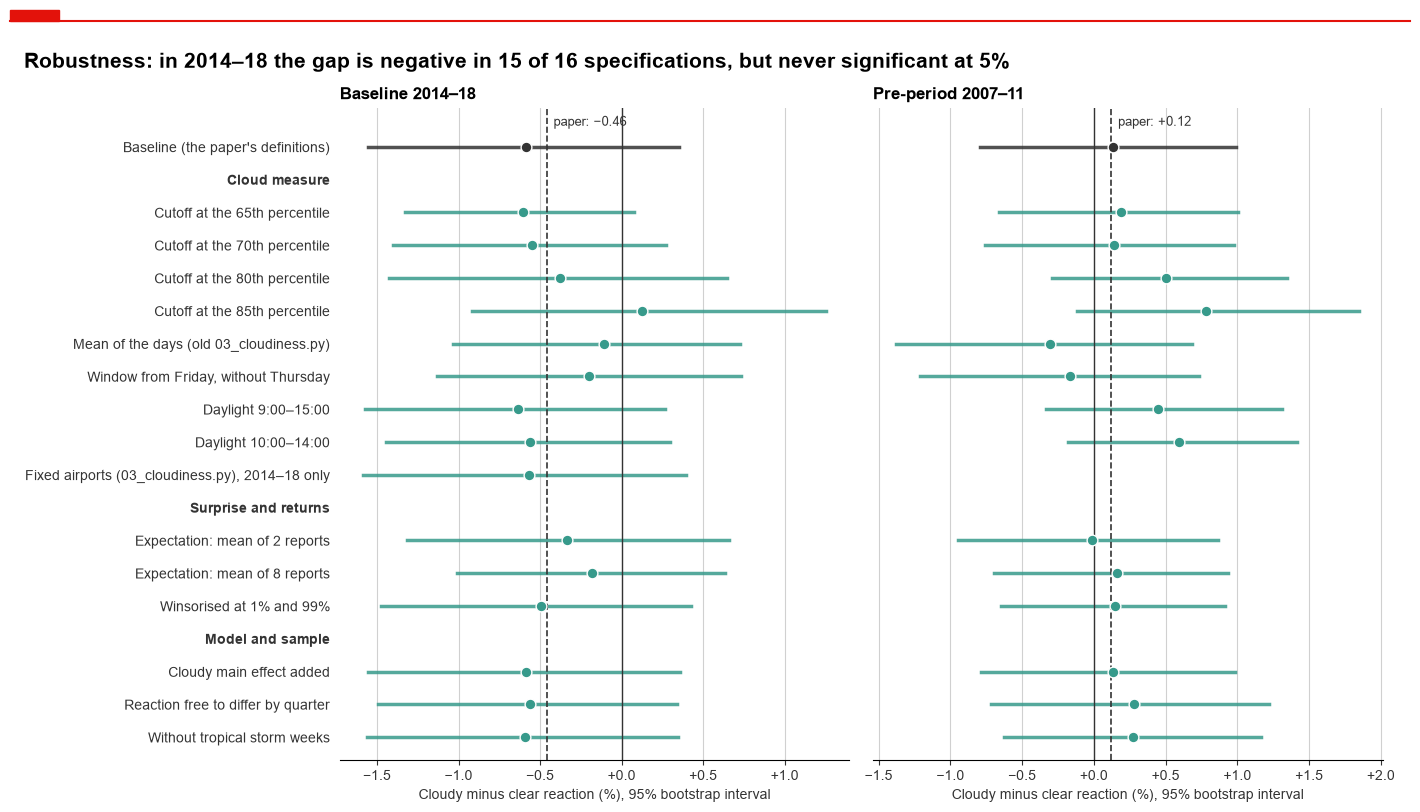

2014–18 gap with the 85th percentile +0.12, mean of the days −0.11, from Friday −0.20, 8-report expectation −0.18; 2007–11 specifications significant at 5%: 0
Fixed airports: daily mean 0.342 (ours 0.330, correlation 0.98), 18 of 260 weeks labelled differently, gap −0.57 (p = 0.22)


In [20]:
layout = []  # (label, is a group header), from the top down
for group, tests in ROBUSTNESS_GROUPS.items():
    layout += ([(group, True)] if group else []) + [(label, False) for label in tests]
positions = np.arange(len(layout))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 7.8), sharey=True)
for ax, period in zip(axes, robustness):
    for (label, header), y in zip(layout, positions):
        if header or label not in robustness[period].index:
            continue
        estimate, low, high = robustness[period].loc[label, ["estimate", "low", "high"]]
        color = DARK if label.startswith("Baseline") else GAP
        ax.plot([low, high], [y, y], color=color, lw=2.5, alpha=0.85)
        ax.scatter(estimate, y, color=color, s=60, zorder=3, edgecolor="white")
    paper_gap = PAPER_TABLES_2_3[period][2][0]
    ax.axvline(paper_gap, color=PAPER, lw=1.2, ls="--")
    annotate(ax, minus_sign(f"paper: {paper_gap:+.2f}"), (paper_gap, positions[0] + 0.75), offset=(5, 0), fontsize=9)
    ax.axvline(0, color=DARK, lw=1)
    ax.set_yticks(positions, [label for label, _ in layout])
    for tick, (_, header) in zip(ax.get_yticklabels(), layout):
        tick.set_fontweight("bold" if header else "normal")
    ax.set_ylim(positions[-1] - 0.7, positions[0] + 1.2)
    ax.set_title(f"{'Baseline' if period == '2014–18' else 'Pre-period'} {period}", fontsize=12.5)
    ax.set_xlabel("Cloudy minus clear reaction (%), 95% bootstrap interval")
    ax.xaxis.set_major_formatter(SIGNED)
    vertical_grid(ax)
negative = (robustness["2014–18"]["estimate"] < 0).sum()
significant = (robustness["2014–18"]["p"] < 0.05).sum()
show(f"Robustness: in 2014–18 the gap is negative in {negative} of {len(robustness['2014–18'])} specifications, "
     + ("but never significant at 5%" if significant == 0 else f"significant at 5% in {significant}"))
SHORT_NAMES = {"Cutoff at the 85th percentile": "85th percentile", "Mean of the days (old 03_cloudiness.py)":
               "mean of the days", "Window from Friday, without Thursday": "from Friday",
               "Expectation: mean of 8 reports": "8-report expectation"}
print(minus_sign("2014–18 gap with the " + ", ".join(f"{short} {robustness['2014–18'].loc[label, 'estimate']:+.2f}"
                                                    for label, short in SHORT_NAMES.items())
                 + f"; 2007–11 specifications significant at 5%: {(robustness['2007–11']['p'] < 0.05).sum()}"))
if "cloud_min_fixed" in reports:
    fixed_week, our_week = weeks_of("2014–18", cloud="cloud_min_fixed"), weeks_of("2014–18")
    fixed_day = pd.read_csv(FIXED_AIRPORTS, index_col=0, parse_dates=True)["cloudiness"]
    fixed_gap = robustness["2014–18"].loc["Fixed airports (03_cloudiness.py), 2014–18 only"]
    print(minus_sign(f"Fixed airports: daily mean {fixed_day.mean():.3f} (ours {daily_cloud[fixed_day.index].mean():.3f}, "
                     f"correlation {fixed_day.corr(daily_cloud):.2f}), {fixed_week['cloudy'].ne(our_week['cloudy']).sum()} "
                     f"of {len(our_week)} weeks labelled differently, gap {fixed_gap['estimate']:+.2f} (p = {fixed_gap['p']:.2f})"))

**Comments – Task #4**
* **A stable sign:** the 2014–18 gap is negative in 15 of 16 specifications and never significant at 5%. It keeps its size under the paper's checks (cutoffs from 65% to 80%, daylight hours, a Cloudy main effect, winsorising), with one fixed airport per hub (−0.57; 18 of 260 weeks change label), without the 5 storm weeks (2 of them cloudy) and within the same quarter.
* **The least cloudy day matters:** averaging the week's days, as `03_cloudiness.py` did before our fix, shrinks the gap to −0.11, a window from Friday to −0.20 and an 8-report expectation to −0.18; the strict 85th percentile flips it to +0.12. So the result hinges on the paper's exact definitions.
* **Pre-period:** the gap scatters around zero and is never significant, as the placebo requires.

## Task #5 – Out of sample: 2019 to April 2024
The paper ends in 2018 and warns that radar satellites, which see through clouds, may weaken the instrument. We rerun Table 2 on 2019 to April 2024 (EIA's last futures prices) and on rolling five-year windows, each with its own cutoff and scaling.

In [21]:
oos = weeks_of("2019–24")
oos_results = {"2019–24": reaction(oos), "2019–24 without 2020": reaction(oos[oos["release"].dt.year != 2020]),
               "2020 only": reaction(oos[oos["release"].dt.year == 2020])}
pd.concat({name: paper_style(result) for name, result in oos_results.items()}, axis=1)

,2019–24,2019–24 without 2020,2020 only
β clear,−0.44** (0.03),−0.24 (0.19),−1.28* (0.05)
β cloudy,0.35 (0.22),0.31 (0.32),0.60 (0.51)
Difference,0.79** (0.03),0.55 (0.14),1.87* (0.07)
R²,0.01,0.01,0.03
Observations,273,220,53


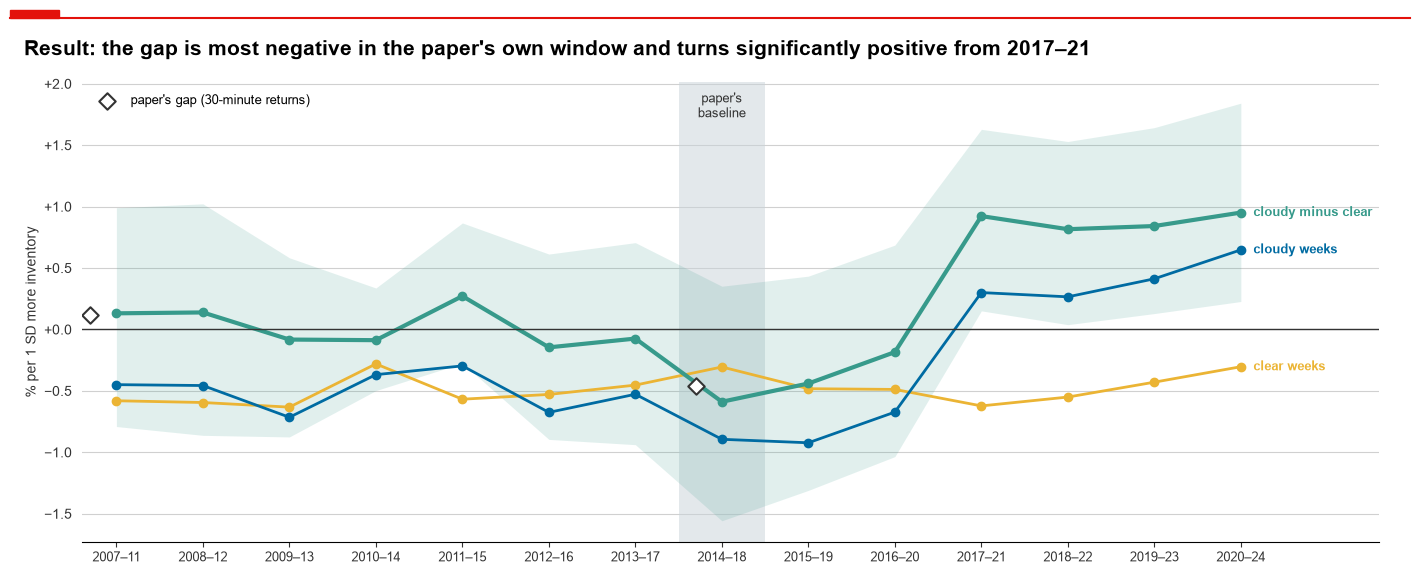

Gap by window: −0.59 at least (window ending 2018), +0.95 at most (ending 2024); significantly negative in 0 windows, significantly positive in 4 (ending 2021, 2022, 2023, 2024)


In [22]:
WINDOW_YEARS = 5  # length of the rolling samples, as the paper's periods
rolling = {}
for last_year in range(2007 + WINDOW_YEARS - 1, 2025):
    sample = weeks_of((f"{last_year - WINDOW_YEARS + 1}-01-01", min(f"{last_year}-12-31", PERIODS["2019–24"][1])))
    rolling[last_year] = reaction(sample).stack()
rolling = pd.DataFrame(rolling).T

fig, ax = plt.subplots(figsize=(14, 5.5))
years = rolling.index
ax.axvspan(2017.5, 2018.5, color=LIGHT_GREY, alpha=0.5, lw=0)
ax.text(2018, 0.98, "paper's\nbaseline", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9,
        color=DARK)
ax.fill_between(years, rolling[("gap", "low")], rolling[("gap", "high")], color=GAP, alpha=0.15, lw=0)
for name, color, width in [("clear", CLEAR, 2), ("cloudy", CLOUDY, 2), ("gap", GAP, 3)]:
    ax.plot(years, rolling[(name, "estimate")], color=color, lw=width, marker="o")
    annotate(ax, {"clear": "clear weeks", "cloudy": "cloudy weeks", "gap": "cloudy minus clear"}[name],
             (years[-1], rolling[(name, "estimate")].iloc[-1]), color=color, fontweight="bold")
for year, period in [(2011, "2007–11"), (2018, "2014–18")]:  # beside our estimate of the same window
    ax.scatter(year - 0.3, PAPER_TABLES_2_3[period][2][0], marker="D", s=70, facecolor="white", edgecolor=PAPER,
               lw=1.5, zorder=4)
ax.scatter([], [], marker="D", s=70, facecolor="white", edgecolor=PAPER, lw=1.5, label="paper's gap (30-minute returns)")
ax.legend(loc="upper left", fontsize=9.5)
ax.axhline(0, color=DARK, lw=1)
ax.set_xticks(years, [f"{year - WINDOW_YEARS + 1}–{str(year)[2:]}" for year in years], rotation=0, fontsize=9)
ax.set_xlim(years[0] - 0.4, years[-1] + 1.6)
ax.yaxis.set_major_formatter(SIGNED)
ax.set_ylabel("% per 1 SD more inventory")
show("Result: the gap is most negative in the paper's own window and turns significantly positive from 2017–21")
negative_windows = rolling.index[rolling[("gap", "high")] < 0]
positive_windows = rolling.index[rolling[("gap", "low")] > 0]
print(minus_sign(f"Gap by window: {rolling[('gap', 'estimate')].min():+.2f} at least (window ending "
                 f"{rolling[('gap', 'estimate')].idxmin()}), {rolling[('gap', 'estimate')].max():+.2f} at most (ending "
                 f"{rolling[('gap', 'estimate')].idxmax()}); significantly negative in {len(negative_windows)} windows, "
                 f"significantly positive in {len(positive_windows)} (ending {', '.join(map(str, positive_windows))})"))

**Comments – Task #5**
* **The gap reverses:** in 2019–24 a 1 SD surprise lowers the price by 0.44% in clear weeks but raises it by 0.35% in cloudy weeks, a gap of +0.79 (p = 0.03). Without 2020 it is +0.55 (p = 0.14); the pandemic year alone gives +1.87.
* **Only the paper's window stands out:** over rolling five-year windows the gap is most negative exactly in 2014–18 (−0.59), never significantly negative, and significantly positive in the four windows ending 2021 to 2024.
* **Reading:** radar satellites that see through clouds would shrink the gap to zero, not reverse it. A reversal suggests that part of the 2014–18 gap was sampling noise, or that cloudy weeks after 2019 differ in other ways (pandemic, war in Ukraine); daily data cannot tell these apart.

## Conclusion

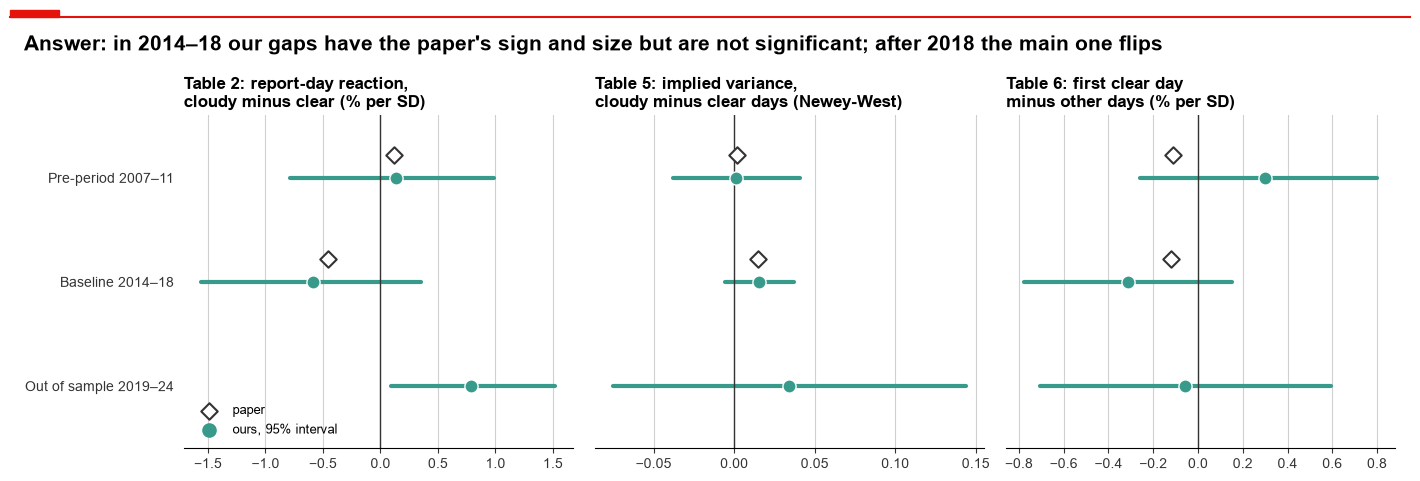

In [23]:
SUMMARY_ROWS = {"2007–11": 2, "2014–18": 1, "2019–24": 0}  # chart rows, oldest on top
INTERVAL = ["estimate", "low", "high"]
nw_interval = {period: pd.Series({"estimate": gap, "low": gap - Z_95 * se, "high": gap + Z_95 * se})
               for period, (gap, se) in ((p, gaps_5[p]["All days (paper)"]) for p in SUMMARY_ROWS)}
summary = {  # panel title: (our estimate and 95% interval by period, the paper's estimate by period)
    "Table 2: report-day reaction,\ncloudy minus clear (% per SD)": (
        {**{p: results[p].loc["gap", INTERVAL] for p in ("2007–11", "2014–18")},
         "2019–24": oos_results["2019–24"].loc["gap", INTERVAL]},
        {p: PAPER_TABLES_2_3[p][2][0] for p in ("2007–11", "2014–18")}),
    "Table 5: implied variance,\ncloudy minus clear days (Newey-West)": (
        nw_interval, {p: PAPER_TABLE_5[p][2] for p in ("2007–11", "2014–18")}),
    "Table 6: first clear day\nminus other days (% per SD)": (
        {p: results_6[p].loc["gap", INTERVAL] for p in SUMMARY_ROWS},
        {p: PAPER_TABLE_6[p][2][0] for p in ("2007–11", "2014–18")}),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, (title, (ours, paper)) in zip(axes, summary.items()):
    for period, row in SUMMARY_ROWS.items():
        estimate, low, high = ours[period]
        ax.plot([low, high], [row, row], color=GAP, lw=3, solid_capstyle="round")
        ax.scatter(estimate, row, color=GAP, s=90, zorder=3, edgecolor="white")
        if period in paper:  # just above our estimate, which it would hide
            ax.scatter(paper[period], row + 0.22, marker="D", s=70, facecolor="white", edgecolor=PAPER, lw=1.5,
                       zorder=4)
    ax.axvline(0, color=DARK, lw=1)
    ax.set_title(title, fontsize=12)
    ax.set_ylim(-0.6, 2.6)
    vertical_grid(ax)
axes[0].set_yticks(list(SUMMARY_ROWS.values()), ["Pre-period 2007–11", "Baseline 2014–18", "Out of sample 2019–24"])
axes[0].scatter([], [], marker="D", s=70, facecolor="white", edgecolor=PAPER, lw=1.5, label="paper")
axes[0].scatter([], [], color=GAP, s=90, label="ours, 95% interval")
axes[0].legend(loc="lower left", fontsize=9.5)
show("Answer: in 2014–18 our gaps have the paper's sign and size but are not significant; after 2018 the main one flips")

* **Main result (Table 2):** with public daily data the 2014–18 reaction is three times as strong in cloudy weeks (−0.89% against −0.31% per SD), a gap close to the paper's, but daily noise leaves it insignificant (p = 0.19; we had 25% power).
* **Placebos (Table 3):** no gap in 2007–11 (+0.13) and no reaction on the days after a report, as in the paper.
* **Mechanism (Tables 5 and 6):** Table 5 replicates to the third decimal, but its significance comes from comparing different months; the first clear day points the paper's way in 2014–18, without significance.
* **Out of sample:** after 2018 the gap reverses (+0.79, p = 0.03; +0.55 without 2020), so the cloud instrument no longer separates informed from uninformed weeks.
* **Next step:** intraday prices, e.g. USO trades from WRDS TAQ (`pipeline/05_download_wrds_uso.py`), would give the test the paper's power: 81% instead of 25% against the paper's gap.

## References
* Mukherjee, A., Panayotov, G. and Shon, J. (2021), Eye in the sky: Private satellites and government macro data, *Journal of Financial Economics* 141, 234–254.
* Newey, W. K. and West, K. D. (1987), A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix, *Econometrica* 55, 703–708.
* U.S. Energy Information Administration: NYMEX futures prices (contracts 1 and 2), Weekly Petroleum Status Report (crude oil stocks excluding SPR, archive of release dates), downloaded November 2026.
* NOAA National Centers for Environmental Information, Integrated Surface Database (hourly sky cover); National Hurricane Center, HURDAT2 best tracks.
* Cboe crude oil volatility index (OVX), via FRED, Federal Reserve Bank of St. Louis.